<a href="https://colab.research.google.com/github/marcelonicolays/tcc_compras_diretas/blob/main/codigo/ML_TCC_compras_diretas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCP - Universidade Católica de Petrópolis
## Projeto de Conclusão de Curso
Marcelo Nicolay Santos

12510824

Dados extraídos no notebook ETL e incluidos no Dataframe no Supabase com o Notebook SQL

* Instalar e importar bibliotecas

In [1]:
!pip install sqlalchemy psycopg2-binary pandas pyarrow
!pip -q install kneed

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 27.8 MB/s  0:00:00


In [2]:
from sqlalchemy import create_engine, text
from getpass import getpass
from google.colab import files
from sqlalchemy.engine import URL
import os
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy import sparse
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from kneed import KneeLocator

from scipy.sparse import issparse, csr_matrix

### Conectar Supabase

In [ ]:
# insere dados do banco
host = input('Host do Session pooler: ').strip()
usuario = input('Usuário do banco: ').strip()
senha = getpass('Senha do banco: ')

# Monta URL
url = URL.create(
    drivername='postgresql+psycopg2',
    username=usuario,
    password=senha,
    host=host,
    port=5432,
    database='postgres'
)

# Cria Engine
engine = create_engine(
    url,
    connect_args={
        'sslmode': 'require',
        'connect_timeout': 15
    },
    pool_pre_ping=True,
    pool_size=1,
    max_overflow=0
)

# Testa a conexão
try:
    with engine.connect() as conn:
        resultado = conn.execute(
            text('SELECT current_database(), current_schema()')
        ).fetchone()

    print('Conexão realizada com sucesso!')
    print(f'Banco: {resultado[0]}')
    print(f'Schema: {resultado[1]}')
except Exception as e:
    print(f'Erro na conexão: {e}')

### Consultar tabelas e verificar dados

In [4]:
# Identifica o schema atual
with engine.connect() as conn:
    schema = conn.execute(
        text("SELECT current_schema()")
    ).scalar_one()

    print(f"Banco de dados: {conn.execute(text('SELECT current_database()')).scalar_one()}")
    print(f"Schema consultado: {schema}")

    # Lista as tabelas existentes
    df_tabelas = pd.read_sql_query(
        text("""
            SELECT table_name
            FROM information_schema.tables
            WHERE table_schema = :schema
              AND table_type = 'BASE TABLE'
            ORDER BY table_name
        """),
        conn,
        params={"schema": schema}
    )

    # Consulta a quantidade de registros de cada tabela
    tabelas_info = []

    preparador = engine.dialect.identifier_preparer
    schema_sql = preparador.quote(schema)

    for tabela in df_tabelas["table_name"]:
        tabela_sql = preparador.quote(tabela)

        quantidade = conn.execute(
            text(f"SELECT COUNT(*) FROM {schema_sql}.{tabela_sql}")
        ).scalar_one()

        tabelas_info.append({
            "Tabela": tabela,
            "Quantidade_registros": quantidade
        })

    df_resumo_tabelas = pd.DataFrame(tabelas_info)

    # Consulta as colunas e seus tipos no PostgreSQL
    df_colunas_sql = pd.read_sql_query(
        text("""
            SELECT
                table_name AS tabela,
                ordinal_position AS ordem,
                column_name AS coluna,
                data_type AS tipo_dado,
                udt_name AS tipo_postgresql,
                is_nullable AS aceita_nulo
            FROM information_schema.columns
            WHERE table_schema = :schema
            ORDER BY table_name, ordinal_position
        """),
        conn,
        params={"schema": schema}
    )

# Apresenta os resultados
print("\n=== TABELAS E QUANTIDADE DE REGISTROS ===")
display(df_resumo_tabelas)

print("\n=== COLUNAS E TIPOS DE DADOS ===")
display(df_colunas_sql)

print(f"\nTotal de tabelas encontradas: {len(df_resumo_tabelas)}")
print(f"Total de colunas encontradas: {len(df_colunas_sql)}")

Banco de dados: postgres
Schema consultado: public

=== TABELAS E QUANTIDADE DE REGISTROS ===


,Tabela,Quantidade_registros
0,afastamento,7
1,categoria_item,1
2,cep,0
3,cnae,0
4,cnae_parte,0
5,esfera,1
6,item,7971
7,itens_processo,20642
8,municipio,0
9,natureza_juridica,1



=== COLUNAS E TIPOS DE DADOS ===


,tabela,ordem,coluna,tipo_dado,tipo_postgresql,aceita_nulo
0,afastamento,1,idafastamento,integer,int4,NO
1,afastamento,2,descricao_afastamento,text,text,YES
2,categoria_item,1,idcategoria_item,integer,int4,NO
3,categoria_item,2,descricao,character varying,varchar,NO
4,cep,1,cep,character varying,varchar,NO
...,...,...,...,...,...,...
99,uf,1,iduf,integer,int4,NO
100,uf,2,uf,character varying,varchar,NO
101,uf,3,nome_estado,character varying,varchar,YES
102,un_medida,1,idun_medida,integer,int4,NO



Total de tabelas encontradas: 24
Total de colunas encontradas: 104


## Montar base analítica

In [6]:
# ============================================================
# CONSULTA DA BASE PARA MACHINE LEARNING — SUPABASE
# ============================================================

consulta_base_ml = """
SELECT
    ip.iditens_processo,
    p.idprocesso,
    p.numero_processo,
    p.ano_processo,
    p.data_aprovacao,
    p.valor_processo,
    p.objeto,
    p.enquadramento,

    o.idorgao,
    o.nome_orgao AS unidade,

    -- FORNECEDOR VINCULADO AO ITEM
    ip.parte_idparte AS fornecedor_id,

    COALESCE(
        NULLIF(BTRIM(pj.razao_social), ''),
        NULLIF(BTRIM(pj.nome_fantasia), ''),
        'Fornecedor não identificado'
    ) AS fornecedor,

    i.iditem,
    i.descricao_item AS item,
    ip.quantidade,
    um.un_medida AS unidade_medida,
    ip.valor_unitario,

    a.descricao_afastamento AS afastamento,
    tc.descricao AS tipo_contratacao

FROM public.itens_processo AS ip

INNER JOIN public.processo AS p
    ON p.idprocesso = ip.processo_idprocesso

INNER JOIN public.processo_compra_direta AS pcd
    ON pcd.processo_idprocesso = p.idprocesso

LEFT JOIN public.orgao AS o
    ON o.idorgao = p.orgao_idorgao

-- RELACIONAMENTO DO FORNECEDOR PELO ITEM
LEFT JOIN public.parte_pj AS pj
    ON pj.parte_idparte = ip.parte_idparte

LEFT JOIN public.item AS i
    ON i.iditem = ip.item_iditem

LEFT JOIN public.un_medida AS um
    ON um.idun_medida = i.un_medida_idun_medida

LEFT JOIN public.afastamento AS a
    ON a.idafastamento = pcd.afastamento_idafastamento

LEFT JOIN public.tipo_contratacao AS tc
    ON tc.idtipo_contratacao = p.tipo_contratacao_idtipo_contratacao

ORDER BY
    p.ano_processo,
    p.idprocesso,
    ip.iditens_processo
"""

# ------------------------------------------------------------
# EXECUTAR CONSULTA
# ------------------------------------------------------------

with engine.connect() as conn:
    df_ml_base = pd.read_sql_query(
        text(consulta_base_ml),
        conn
    )

# ------------------------------------------------------------
# PADRONIZAR TIPOS DE DADOS
# ------------------------------------------------------------

for coluna in [
    'valor_processo',
    'quantidade',
    'valor_unitario'
]:
    df_ml_base[coluna] = pd.to_numeric(
        df_ml_base[coluna],
        errors='coerce'
    ).astype('float64')

df_ml_base['data_aprovacao'] = pd.to_datetime(
    df_ml_base['data_aprovacao'],
    errors='coerce'
)

# ------------------------------------------------------------
# RELATÓRIO DA EXTRAÇÃO
# ------------------------------------------------------------

print("=" * 70)
print("BASE EXTRAÍDA DO SUPABASE — MACHINE LEARNING")
print("=" * 70)

print(f"Registros de itens: {len(df_ml_base):,}")

print(
    f"Processos distintos: "
    f"{df_ml_base['idprocesso'].nunique():,}"
)

print(
    f"Itens distintos: "
    f"{df_ml_base['iditens_processo'].nunique():,}"
)

print(
    f"Processos sem órgão identificado: "
    f"{df_ml_base['unidade'].isna().sum():,}"
)

print(
    f"Itens sem fornecedor identificado: "
    f"{df_ml_base['fornecedor'].eq('Fornecedor não identificado').sum():,}"
)

print(
    f"Itens sem fornecedor_id: "
    f"{df_ml_base['fornecedor_id'].isna().sum():,}"
)

print("\nTipos de dados:")
display(df_ml_base.dtypes.to_frame('tipo_dado'))

print("\nAmostra da base:")
display(df_ml_base.head())


BASE EXTRAÍDA DO SUPABASE — MACHINE LEARNING
Registros de itens: 20,642
Processos distintos: 12,228
Itens distintos: 20,642
Processos sem órgão identificado: 0
Itens sem fornecedor identificado: 0
Itens sem fornecedor_id: 0

Tipos de dados:


,tipo_dado
iditens_processo,int64
idprocesso,int64
numero_processo,object
ano_processo,int64
data_aprovacao,datetime64[ns]
valor_processo,float64
objeto,object
enquadramento,object
idorgao,int64
unidade,object



Amostra da base:


,iditens_processo,idprocesso,numero_processo,ano_processo,data_aprovacao,valor_processo,objeto,enquadramento,idorgao,unidade,fornecedor_id,fornecedor,iditem,item,quantidade,unidade_medida,valor_unitario,afastamento,tipo_contratacao
0,1,1,**SEI-120001/009348/2022,2023,2023-07-05,10994.00,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,"De acordo com o artigo24, inciso 2º da Lei Fed...",1,SEPLAG - Secretaria de Estado de Planejamento ...,4001,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,1,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,1.0,SERVICO,10994.00,Dispensa - Pequenas Compras,Compra Direta
1,65,61,020002/000814/2023,2023,2023-07-13,7199.28,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3967,LESTE GROUP TELECOMUNICACOES DO BRASIL LTDA,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,599.94,Dispensa - Pequenas Compras,Compra Direta
2,66,62,020002/000819/2023,2023,2023-07-13,3599.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,"Dispensa Licitação no artigo 29, Inciso II da ...",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3966,GIGALINK DE NOVA FRIBURGO SOLUCOES EM REDE MUL...,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,299.98,Dispensa - Pequenas Compras,Compra Direta
3,67,63,020002/000821/2023,2023,2023-07-13,4079.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 Art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3965,TELEFONICA BRASIL S/A.,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,339.98,Dispensa - Pequenas Compras,Compra Direta
4,71,66,020002/000917/2023,2023,2023-08-21,234999.96,1 FORNECIMENTO DE ENERGIA ELETRICADESCRIÇÃO CO...,"Art. 29, Inciso X da Lei Federal nº 13.303/16",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3988,AMPLA ENERGIA E SERVIÇOS S/A,3,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,6.0,SERVICO,39166.66,Dispensa - Especial,Compra Direta


### Montar base através do df_limpo.parquet

In [14]:
# ============================================================
# IMPORTAÇÃO DA BASE PARA MACHINE LEARNING VIA PARQUET
# ============================================================

# ALTERNATIVA:
# Caso o usuário não possua acesso ao Supabase,
# disponibilizar o arquivo base_ml.parquet no ambiente
# de execução do Colab (/content) e utilizar esta célula
# para carregar a base previamente extraída do banco de dados.

# ------------------------------------------------------------
# 1. LOCALIZAR E CARREGAR O ARQUIVO
# ------------------------------------------------------------

from pathlib import Path
import pandas as pd

arquivo_parquet = Path('/content/base_ml.parquet')

if not arquivo_parquet.exists():
    raise FileNotFoundError(
        "Arquivo base_ml.parquet não encontrado em /content. "
        "Disponibilize o arquivo no ambiente de execução."
    )

df_ml_base = pd.read_parquet(
    arquivo_parquet,
    engine='pyarrow'
)

# ------------------------------------------------------------
# 2. VALIDAR A IMPORTAÇÃO
# ------------------------------------------------------------

if df_ml_base.empty:
    raise ValueError("O arquivo Parquet não contém registros.")

colunas_obrigatorias = [
    'iditens_processo',
    'idprocesso',
    'numero_processo',
    'ano_processo',
    'data_aprovacao',
    'valor_processo',
    'objeto',
    'enquadramento',
    'idorgao',
    'unidade',
    'fornecedor_id',
    'fornecedor',
    'iditem',
    'item',
    'quantidade',
    'unidade_medida',
    'valor_unitario',
    'afastamento',
    'tipo_contratacao'
]

colunas_ausentes = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in df_ml_base.columns
]

if colunas_ausentes:
    raise ValueError(
        f"Colunas obrigatórias ausentes: {colunas_ausentes}"
    )

if df_ml_base['iditens_processo'].isna().any():
    raise ValueError(
        "Existem identificadores de itens nulos."
    )

if df_ml_base['iditens_processo'].duplicated().any():
    raise ValueError(
        "Existem identificadores de itens duplicados."
    )

# ------------------------------------------------------------
# 3. PADRONIZAR TIPOS DE DADOS
# ------------------------------------------------------------

for coluna in [
    'valor_processo',
    'quantidade',
    'valor_unitario'
]:
    df_ml_base[coluna] = pd.to_numeric(
        df_ml_base[coluna],
        errors='coerce'
    ).astype('float64')

df_ml_base['data_aprovacao'] = pd.to_datetime(
    df_ml_base['data_aprovacao'],
    errors='coerce'
)

df_ml_base['ano_processo'] = pd.to_numeric(
    df_ml_base['ano_processo'],
    errors='coerce'
).astype('Int64')

# ------------------------------------------------------------
# 4. RELATÓRIO DA IMPORTAÇÃO
# ------------------------------------------------------------

print("=" * 70)
print("BASE DE MODELAGEM IMPORTADA VIA PARQUET")
print("=" * 70)

print(f"Registros de itens: {len(df_ml_base):,}")

print(
    f"Processos distintos: "
    f"{df_ml_base['idprocesso'].nunique():,}"
)

print(
    f"Itens distintos: "
    f"{df_ml_base['iditens_processo'].nunique():,}"
)

print(
    f"Processos sem órgão identificado: "
    f"{df_ml_base['unidade'].isna().sum():,}"
)

print(
    f"Itens sem fornecedor identificado: "
    f"{df_ml_base['fornecedor'].eq('Fornecedor não identificado').sum():,}"
)

print(
    f"Itens sem fornecedor_id: "
    f"{df_ml_base['fornecedor_id'].isna().sum():,}"
)

print(
    f"\nArquivo utilizado: {arquivo_parquet}"
)

print(
    f"Tamanho: "
    f"{arquivo_parquet.stat().st_size / (1024**2):.2f} MB"
)

print("\nTipos de dados:")
display(df_ml_base.dtypes.to_frame('tipo_dado'))

print("\nAmostra da base:")
display(df_ml_base.head())

print("\nImportação e validação concluídas.")


BASE DE MODELAGEM IMPORTADA VIA PARQUET
Registros de itens: 20,642
Processos distintos: 12,228
Itens distintos: 20,642
Processos sem órgão identificado: 0
Itens sem fornecedor identificado: 0
Itens sem fornecedor_id: 0

Arquivo utilizado: /content/base_ml.parquet
Tamanho: 2.68 MB

Tipos de dados:


,tipo_dado
iditens_processo,int64
idprocesso,int64
numero_processo,object
ano_processo,Int64
data_aprovacao,datetime64[ns]
valor_processo,float64
objeto,object
enquadramento,object
idorgao,int64
unidade,object



Amostra da base:


,iditens_processo,idprocesso,numero_processo,ano_processo,data_aprovacao,valor_processo,objeto,enquadramento,idorgao,unidade,fornecedor_id,fornecedor,iditem,item,quantidade,unidade_medida,valor_unitario,afastamento,tipo_contratacao
0,1,1,**SEI-120001/009348/2022,2023,2023-07-05,10994.00,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,"De acordo com o artigo24, inciso 2º da Lei Fed...",1,SEPLAG - Secretaria de Estado de Planejamento ...,4001,MAR E FIRE EQUIP. E PROT. CONTRA INCÊNDIO LTDA-ME,1,MANUTENCAO EM EXTINTORES DE INCENDIO - DESCRI...,1.0,SERVICO,10994.00,Dispensa - Pequenas Compras,Compra Direta
1,65,61,020002/000814/2023,2023,2023-07-13,7199.28,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3967,LESTE GROUP TELECOMUNICACOES DO BRASIL LTDA,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,599.94,Dispensa - Pequenas Compras,Compra Direta
2,66,62,020002/000819/2023,2023,2023-07-13,3599.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,"Dispensa Licitação no artigo 29, Inciso II da ...",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3966,GIGALINK DE NOVA FRIBURGO SOLUCOES EM REDE MUL...,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,299.98,Dispensa - Pequenas Compras,Compra Direta
3,67,63,020002/000821/2023,2023,2023-07-13,4079.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 Art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3965,TELEFONICA BRASIL S/A.,12,SERVICOS DE ACESSO A INTERNET - DESCRIÇÃO: CON...,12.0,SERVICO,339.98,Dispensa - Pequenas Compras,Compra Direta
4,71,66,020002/000917/2023,2023,2023-08-21,234999.96,1 FORNECIMENTO DE ENERGIA ELETRICADESCRIÇÃO CO...,"Art. 29, Inciso X da Lei Federal nº 13.303/16",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,3988,AMPLA ENERGIA E SERVIÇOS S/A,3,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,6.0,SERVICO,39166.66,Dispensa - Especial,Compra Direta



Importação e validação concluídas.


### Preparação das variáveis

In [15]:
# PREPARAÇÃO DA BASE
df_ml = df_ml_base.copy()

colunas_necessarias = [
    'idprocesso', 'fornecedor_id', 'idorgao',
    'valor_processo', 'valor_unitario', 'quantidade',
    'afastamento', 'unidade'
]

faltantes = [c for c in colunas_necessarias if c not in df_ml.columns]
if faltantes:
    raise ValueError(f"Colunas necessárias não encontradas: {faltantes}")

print(f"Registros de itens: {len(df_ml):,}")

# AGREGAÇÕES DO FORNECEDOR
print("\nCalculando os agregados dos fornecedores...")

# Criamos a coluna de valor total do item para facilitar a soma
df_ml['valor_total_item'] = df_ml['valor_unitario'] * df_ml['quantidade']

# Número de órgãos distintos atendidos e Valor Acumulado por fornecedor
agg_forn = (
    df_ml.groupby('fornecedor_id', dropna=False)
    .agg(
        n_orgaos_fornecedor=('idorgao', 'nunique'),           # Unidades atendidas
        valor_total_fornecedor=('valor_total_item', 'sum')    # Valor acumulado
    )
    .reset_index()
)

# Número de processos distintos por fornecedor e órgão
agg_forn_orgao = (
    df_ml.groupby(['fornecedor_id', 'idorgao'], dropna=False)
    .agg(
        freq_fornecedor_orgao=('idprocesso', 'nunique')
    )
    .reset_index()
)

# Remover versões anteriores e incorporar os novos agregados
df_ml = df_ml.drop(
    columns=['n_orgaos_fornecedor', 'freq_fornecedor_orgao', 'valor_total_fornecedor'],
    errors='ignore'
)

df_ml = df_ml.merge(agg_forn, on='fornecedor_id', how='left', validate='many_to_one')
df_ml = df_ml.merge(agg_forn_orgao, on=['fornecedor_id', 'idorgao'], how='left', validate='many_to_one')

if len(df_ml) != len(df_ml_base):
    raise ValueError("A quantidade de registros mudou após as agregações.")


# VALIDAÇÃO E TRANSFORMAÇÕES NUMÉRICAS
print("\nValidando as variáveis numéricas...")

colunas_originais_num = ['valor_processo', 'valor_unitario', 'quantidade']
for coluna in colunas_originais_num:
    df_ml[coluna] = pd.to_numeric(df_ml[coluna], errors='coerce')

ausentes = df_ml[colunas_originais_num].isna().sum()
if ausentes.any():
    raise ValueError(f"Valores ausentes encontrados:\n{ausentes[ausentes > 0]}")

if not np.isfinite(df_ml[colunas_originais_num].to_numpy(dtype=float)).all():
    raise ValueError("Existem valores infinitos nas variáveis numéricas.")

negativos = (df_ml[colunas_originais_num] < 0).sum()
if negativos.any():
    raise ValueError(f"Existem valores negativos:\n{negativos[negativos > 0]}")

# Aplicar log1p: ln(1 + x)
df_ml['log_valor_processo'] = np.log1p(df_ml['valor_processo'])
df_ml['log_valor_unitario'] = np.log1p(df_ml['valor_unitario'])
df_ml['log_quantidade'] = np.log1p(df_ml['quantidade'])
df_ml['log_valor_fornecedor'] = np.log1p(df_ml['valor_total_fornecedor']) # Log do valor acumulado


# Aplicar log1p nas variáveis de contagem (caudas pesadas)
df_ml['log_n_orgaos_fornecedor'] = np.log1p(df_ml['n_orgaos_fornecedor'])
df_ml['log_freq_fornecedor_orgao'] = np.log1p(df_ml['freq_fornecedor_orgao'])

# DEFINIÇÃO DAS FEATURES
features_num = [
    'log_valor_processo',
    'log_valor_unitario',
    'log_quantidade',
    'log_valor_fornecedor',
    'log_n_orgaos_fornecedor',
    'log_freq_fornecedor_orgao'
]
# Removemos 'unidade', mantendo apenas 'afastamento'
features_cat = ['afastamento']

# Garantir que a categoria esteja preenchida
for coluna in features_cat:
    df_ml[coluna] = df_ml[coluna].astype('string').fillna('NÃO IDENTIFICADO').astype(str)

# PRÉ-PROCESSAMENTO
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=True)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), features_num),
        ('cat', encoder, features_cat)
    ],
    remainder='drop',
    sparse_threshold=1.0
)

# Criar a matriz de features
X = preprocessor.fit_transform(df_ml[features_num + features_cat])
if sparse.issparse(X):
    X = X.tocsr()

nomes_features_ml = preprocessor.get_feature_names_out()


# CONFERÊNCIA FINAL
print("\nPreparação concluída.")
print(f"\nLinhas da base: {len(df_ml):,}")
print(f"Features numéricas: {len(features_num)}")
print(f"Variáveis categóricas originais: {len(features_cat)}")
print(f"Total de colunas após o encoding: {X.shape[1]:,}")
print(f"Dimensões da matriz X: {X.shape}")
print("Formato da matriz:", "esparsa" if sparse.issparse(X) else "densa")

print("\nFeatures numéricas:")
for coluna in features_num:
    print(f" - {coluna}")

print("\nPrimeiras colunas geradas pelo encoding:")
for coluna in nomes_features_ml[:10]:
    print(f" - {coluna}")

if X.shape[0] != len(df_ml):
    raise ValueError("O número de linhas de X não corresponde à base.")

print("\nMatriz X pronta para os métodos de ML.")

Registros de itens: 20,642

Calculando os agregados dos fornecedores...

Validando as variáveis numéricas...

Preparação concluída.

Linhas da base: 20,642
Features numéricas: 6
Variáveis categóricas originais: 1
Total de colunas após o encoding: 13
Dimensões da matriz X: (20642, 13)
Formato da matriz: esparsa

Features numéricas:
 - log_valor_processo
 - log_valor_unitario
 - log_quantidade
 - log_valor_fornecedor
 - log_n_orgaos_fornecedor
 - log_freq_fornecedor_orgao

Primeiras colunas geradas pelo encoding:
 - num__log_valor_processo
 - num__log_valor_unitario
 - num__log_quantidade
 - num__log_valor_fornecedor
 - num__log_n_orgaos_fornecedor
 - num__log_freq_fornecedor_orgao
 - cat__afastamento_Dispensa - Especial
 - cat__afastamento_Dispensa - Pequenas Compras
 - cat__afastamento_Dispensa de Licitação
 - cat__afastamento_Dispensa de Licitação 13.303/2016

Matriz X pronta para os métodos de ML.


##  Análise de Z-Score

In [16]:
# Z-score dos preços unitários por item e unidade de medida

colunas_grupo = ['item', 'unidade_medida']

grupo_preco = df_ml.groupby(colunas_grupo, dropna=False)['valor_unitario']

# Estatísticas de cada grupo
n_observacoes = grupo_preco.transform('count')
media_preco = grupo_preco.transform('mean')
desvio_preco = grupo_preco.transform(lambda s: s.std(ddof=0))

# Condição de validade: pelo menos 1 observação e desvio > 0
condicao_valida = (n_observacoes >= 1) & (desvio_preco > 0)

# Z-score: distância em desvios-padrão em relação à média
df_ml['zscore_preco'] = (
    (df_ml['valor_unitario'] - media_preco) / desvio_preco
).where(condicao_valida)

# Sinalizar preços pelo menos 2 desvios-padrão acima da média
df_ml['anomalia_zscore'] = (
    df_ml['zscore_preco'].ge(2)
    .where(df_ml['zscore_preco'].notna(), pd.NA)
    .astype('boolean')
)

# Resumo dos resultados
total_itens = len(df_ml)
itens_avaliaveis = df_ml['zscore_preco'].notna().sum()
total_anomalias = df_ml['anomalia_zscore'].sum()

print('ANÁLISE DE Z-SCORE DOS PREÇOS UNITÁRIOS')
print('-' * 45)
print(f'Total de registros: {total_itens:,}')
print(f'Registros avaliáveis: {itens_avaliaveis:,}')
print(f"Registros não avaliáveis (NA): {df_ml['anomalia_zscore'].isna().sum():,}")
print(f'Preços com Z-score >= 2: {total_anomalias:,}')

if itens_avaliaveis > 0:
    percentual = 100 * total_anomalias / itens_avaliaveis
    print(f'Percentual entre os avaliáveis: {percentual:.2f}%')

# ============================================================================
# DIAGNÓSTICO DA COBERTURA (atende ao item 2.4 do relatório)
# ============================================================================
grupos = df_ml.groupby(colunas_grupo, dropna=False)['valor_unitario'].agg(['count', 'std'])
n_grupos = len(grupos)
n_grupos_pequenos = (grupos['count'] < 5).sum()
itens_em_grupos_pequenos = grupos.loc[grupos['count'] < 5, 'count'].sum()

print('\n--- COBERTURA DO Z-SCORE ---')
print(f'Total de grupos (item × unidade): {n_grupos:,}')
print(f'Grupos com < 5 observações: {n_grupos_pequenos:,} '
      f'({100 * n_grupos_pequenos / n_grupos:.1f}%)')
print(f'Itens em grupos com < 5 observações: {itens_em_grupos_pequenos:,} '
      f'({100 * itens_em_grupos_pequenos / total_itens:.1f}%)')
print(f'Itens sem Z calculável: {df_ml["zscore_preco"].isna().sum():,} '
      f'({100 * df_ml["zscore_preco"].isna().sum() / total_itens:.1f}%)')

# ============================================================================
# ANÁLISE DE SENSIBILIDADE AO LIMIAR (atende ao item 2.4)
# ============================================================================
print('\n--- SENSIBILIDADE AO LIMIAR ---')
for limiar in [1.5, 2.0, 2.5, 3.0]:
    sinalizados = (df_ml['zscore_preco'] >= limiar).sum()
    pct_avaliaveis = 100 * sinalizados / itens_avaliaveis if itens_avaliaveis > 0 else 0
    print(f'Z >= {limiar}: {sinalizados:,} itens ({pct_avaliaveis:.2f}% dos avaliáveis)')

# ============================================================================
# EXIBIÇÃO DOS 10 MAIORES Z-SCORES
# ============================================================================
colunas_exibicao = [
    'item', 'unidade_medida', 'fornecedor', 'unidade',
    'valor_unitario', 'zscore_preco', 'anomalia_zscore'
]
display(df_ml.nlargest(10, 'zscore_preco')[colunas_exibicao].reset_index(drop=True))

ANÁLISE DE Z-SCORE DOS PREÇOS UNITÁRIOS
---------------------------------------------
Total de registros: 20,642
Registros avaliáveis: 14,179
Registros não avaliáveis (NA): 6,463
Preços com Z-score >= 2: 367
Percentual entre os avaliáveis: 2.59%

--- COBERTURA DO Z-SCORE ---
Total de grupos (item × unidade): 7,971
Grupos com < 5 observações: 7,488 (93.9%)
Itens em grupos com < 5 observações: 9,656 (46.8%)
Itens sem Z calculável: 6,463 (31.3%)

--- SENSIBILIDADE AO LIMIAR ---
Z >= 1.5: 655 itens (4.62% dos avaliáveis)
Z >= 2.0: 367 itens (2.59% dos avaliáveis)
Z >= 2.5: 230 itens (1.62% dos avaliáveis)
Z >= 3.0: 167 itens (1.18% dos avaliáveis)


,item,unidade_medida,fornecedor,unidade,valor_unitario,zscore_preco,anomalia_zscore
0,SERVICO DE PRODUCAO ARTISTICA - DESCRICAO: CON...,SERVICO,BONUS TRACK ENTRETENIMENTO LTDA,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,15000000.00,30.350437,True
1,SERVICO DE PRODUCAO ARTISTICA - DESCRICAO: CON...,SERVICO,BONUS TRACK ENTRETENIMENTO LTDA,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,10000000.00,20.164055,True
2,SERVICO DE FORNECIMENTO DE AGUA E COLETA DE ES...,SERVICO,F AB ZONA OESTE S A,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,49531444.05,14.582276,True
3,PARTICIPACAO EM CONGRESSOS / SIMPOSIO - DESCRI...,VAGA,"LAVORO GERENCIAMENTO EMPRESARIAL, CORPORATIVO ...",FDRM-RJ - Fundo de Desenv. da Região Metropoli...,86900.00,13.644885,True
4,SERVICO DE PRODUCAO ARTISTICA - DESCRICAO: CON...,SERVICO,LIGA DAS ESCOLAS DE SAMBA DO RIO DE JANEIRO - ...,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,6500000.00,13.033587,True
5,SERVICO DE PRODUCAO ARTISTICA - DESCRICAO: CON...,SERVICO,LIGA INDEPENDENTE DO GRUPO A - RIO DE JANEIRO,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,6500000.00,13.033587,True
6,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,SERVICO,AGUAS DO RIO 4 SPE S.A,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,34401406.91,11.916197,True
7,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,SERVICO,AGUAS DO RIO 4 SPE S.A,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,33440197.32,11.576775,True
8,PARTICIPACAO EM SEMINARIOS - DESCRIÇÃO: INSCRI...,VAGA,ORZIL CONSULTORIA E TREINAMENTO LTDA EPP,FUNESBOM - FUNDO ESPECIAL DO CORPO DE BOMBEIROS,101995.20,10.912251,True
9,SERVICOS DE ORGANIZACAO DE EVENTOS - DESCRIÇÃO...,SERVICO,ONIX ORGANIZACAO E PRODUCAO DE EVENTOS LTDA,LOTERJ - LOTERIA DO ESTADO DO RIO DE JANEIRO,14000000.00,10.389957,True


* Análise de Z-score — Resultados Estatísticos

A aplicação do Z-score sobre os preços unitários, agrupados por descrição do item e unidade de medida, foi realizada sobre 20.642 registros, dos quais 14.179 (68,7%) apresentaram condições para o cálculo do escore e 6.463 (31,3%) foram classificados como não avaliáveis. Entre os registros avaliáveis, 367 foram sinalizados com Z maior ou igual a 2, o que corresponde a 2,59% desse subconjunto. O cálculo adotou desvio-padrão populacional (ddof = 0), sinalização restrita à cauda superior e preservação da distinção entre registros não avaliáveis (NA) e registros não sinalizados (False).

Em relação à cobertura, foram identificados 7.971 grupos formados pela combinação entre descrição do item e unidade de medida. Desses, 7.488 (93,9%) reúnem menos de cinco observações e concentram 9.656 itens (46,8% da base), enquanto os 6.463 itens sem Z calculável representam 31,3% do total. Esse comportamento é compatível com o limite teórico da medida: em um grupo com n observações, o Z máximo possível é igual à raiz quadrada de (n − 1), de modo que grupos com menos de cinco observações não permitem que qualquer item atinja Z maior ou igual a 2.

A análise de sensibilidade ao limiar mostrou que a quantidade de itens sinalizados varia de forma monotônica com o critério adotado: com Z maior ou igual a 1,5, foram sinalizados 655 itens (4,62% dos avaliáveis); com Z maior ou igual a 2,0, 367 itens (2,59%); com Z maior ou igual a 2,5, 230 itens (1,62%); e com Z maior ou igual a 3,0, 167 itens (1,18%). O limiar de 2,0 foi o adotado nesta etapa, e os demais valores são apresentados para documentar o comportamento da medida sob critérios alternativos.

## Modelos de Aprendizado

## Isolation Forest

In [17]:
# ============================================================
# TREINAMENTO DO MODELO
# ============================================================

print("Treinando o Isolation Forest...")

modelo_iforest = IsolationForest(
    n_estimators=300,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

modelo_iforest.fit(X)

# ============================================================
# CLASSIFICAÇÃO DOS REGISTROS
# ============================================================

# 1 = normal
# -1 = anomalia identificada pelo modelo

df_ml['iforest_pred'] = modelo_iforest.predict(X)

# Score original: valores menores indicam maior anomalia
df_ml['score_iforest'] = modelo_iforest.score_samples(X)

# Score invertido: valores maiores indicam maior atipicidade
df_ml['score_anomalia_iforest'] = -df_ml['score_iforest']

df_ml['anomalia_iforest'] = (
    df_ml['iforest_pred'] == -1
)


# ============================================================
# RESUMO GERAL DOS RESULTADOS
# ============================================================

total = len(df_ml)
total_anomalias = int(df_ml['anomalia_iforest'].sum())
total_normais = total - total_anomalias

print("\nRESULTADOS GERAIS DO ISOLATION FOREST")
print("-" * 60)
print(f"Total de registros (itens): {total:,}")
print(f"Registros normais: {total_normais:,}")
print(f"Anomalias identificadas: {total_anomalias:,}")
print(f"Percentual de itens sinalizados: {total_anomalias / total:.2%}")


# ============================================================
# ANÁLISE POR PROCESSO
# ============================================================

print("\nANÁLISE POR PROCESSO")
print("-" * 60)

total_processos = df_ml['idprocesso'].nunique()

processos_impactados = (
    df_ml.loc[df_ml['anomalia_iforest'], 'idprocesso'].nunique()
)

print(f"Total de processos únicos: {total_processos:,}")
print(f"Processos com pelo menos 1 item sinalizado: {processos_impactados:,}")
print(f"Percentual de processos impactados: {processos_impactados / total_processos:.2%}")

resumo_processos = (
    df_ml.groupby('idprocesso')
    .agg(
        total_itens=('anomalia_iforest', 'size'),
        itens_anomalia=('anomalia_iforest', 'sum')
    )
    .reset_index()
)

qtd_processos_100 = len(
    resumo_processos[
        resumo_processos['itens_anomalia'] ==
        resumo_processos['total_itens']
    ]
)

print(f"\nProcessos com 100% dos itens sinalizados: {qtd_processos_100:,}")

resumo_processos['percentual_anomalia'] = (
    resumo_processos['itens_anomalia'] /
    resumo_processos['total_itens']
) * 100

processos_com_anomalia = resumo_processos[
    resumo_processos['itens_anomalia'] > 0
]

print("\nDISTRIBUIÇÃO DO PERCENTUAL DE ITENS SINALIZADOS")
print("-" * 60)
print(f"Média: {processos_com_anomalia['percentual_anomalia'].mean():.2f}%")
print(f"Mediana: {processos_com_anomalia['percentual_anomalia'].median():.2f}%")
print(f"Máximo: {processos_com_anomalia['percentual_anomalia'].max():.2f}%")
print(f"Mínimo: {processos_com_anomalia['percentual_anomalia'].min():.2f}%")


# ============================================================
# TOP 10 PROCESSOS COM MAIOR PERCENTUAL DE ITENS SINALIZADOS
# ============================================================

print("\nTOP 10 PROCESSOS COM MAIOR PERCENTUAL DE ITENS SINALIZADOS")
print("-" * 60)

top_processos = (
    processos_com_anomalia
    .sort_values('percentual_anomalia', ascending=False)
    .head(10)
    .round(2)
)

display(top_processos)


# ============================================================
# TOP 15 ITENS COM MAIOR SCORE DE ATIPICIDADE
# ============================================================

print("\n15 ITENS SINALIZADOS COM MAIOR SCORE DE ATIPICIDADE")
print("-" * 60)

colunas_exibicao = [
    coluna for coluna in [
        'numero_processo',
        'ano_processo',
        'unidade',
        'fornecedor',
        'item',
        'quantidade',
        'valor_unitario',
        'valor_processo',
        'afastamento',
        'score_anomalia_iforest'
    ]
    if coluna in df_ml.columns
]

display(
    df_ml.loc[df_ml['anomalia_iforest'], colunas_exibicao]
    .sort_values('score_anomalia_iforest', ascending=False)
    .head(15)
    .round(4)
)


# ============================================================
# ANÁLISE DE SENSIBILIDADE - CONTAMINATION
# ============================================================

print("\nANÁLISE DE SENSIBILIDADE DO ISOLATION FOREST")
print("-" * 60)

# Mantém a mesma matriz X e varia somente o contamination.
# O modelo principal com 5% já foi treinado anteriormente.

valores_contamination = [0.03, 0.04, 0.05, 0.06, 0.07]

# Identificação dos itens sinalizados pelo modelo principal
itens_principal = df_ml['anomalia_iforest'].to_numpy()

# Processos sinalizados pelo modelo principal
processos_principal = set(
    df_ml.loc[df_ml['anomalia_iforest'], 'idprocesso']
)

resultados_sensibilidade = []

for contaminacao in valores_contamination:

    if contaminacao == 0.05:
        # Reutiliza o modelo principal
        predicoes = modelo_iforest.predict(X)
    else:
        modelo_teste = IsolationForest(
            n_estimators=300,
            contamination=contaminacao,
            random_state=42,
            n_jobs=-1
        )

        modelo_teste.fit(X)
        predicoes = modelo_teste.predict(X)

    # Identificação das anomalias
    mascara_anomalias = predicoes == -1

    quantidade_itens = int(mascara_anomalias.sum())

    processos_sinalizados = set(
        df_ml.loc[mascara_anomalias, 'idprocesso']
    )

    quantidade_processos = len(processos_sinalizados)

    # Comparação com o modelo principal (5%)
    intersecao = mascara_anomalias & itens_principal

    itens_comuns = int(intersecao.sum())

    # Índice de Jaccard entre os conjuntos de itens sinalizados
    uniao = int((mascara_anomalias | itens_principal).sum())

    jaccard = itens_comuns / uniao if uniao > 0 else 0

    # Processos em comum com o modelo principal
    processos_comuns = len(
        processos_sinalizados & processos_principal
    )

    resultados_sensibilidade.append({
        'Contamination': f'{contaminacao:.0%}',
        'Itens sinalizados': quantidade_itens,
        '% dos itens': quantidade_itens / len(df_ml) * 100,
        'Processos sinalizados': quantidade_processos,
        'Itens em comum c/ 5%': itens_comuns,
        'Jaccard c/ 5%': jaccard * 100,
        'Processos em comum c/ 5%': processos_comuns
    })

df_sensibilidade_iforest = pd.DataFrame(
    resultados_sensibilidade
)

display(
    df_sensibilidade_iforest.style.format({
        '% dos itens': '{:.2f}%',
        'Jaccard c/ 5%': '{:.2f}%'
    })
)

print("\nOBSERVAÇÃO METODOLÓGICA:")
print(
    "O parâmetro contamination influencia o limite de decisão "
    "utilizado pelo Isolation Forest. Portanto, a quantidade de "
    "itens sinalizados depende também dessa escolha de parametrização, "
    "não representando uma taxa de irregularidades comprovadas."
)

print("\nModelo principal treinado com contamination = 5%.")
print("Os resultados principais permanecem armazenados em df_ml.")


Treinando o Isolation Forest...

RESULTADOS GERAIS DO ISOLATION FOREST
------------------------------------------------------------
Total de registros (itens): 20,642
Registros normais: 19,609
Anomalias identificadas: 1,033
Percentual de itens sinalizados: 5.00%

ANÁLISE POR PROCESSO
------------------------------------------------------------
Total de processos únicos: 12,228
Processos com pelo menos 1 item sinalizado: 698
Percentual de processos impactados: 5.71%

Processos com 100% dos itens sinalizados: 644

DISTRIBUIÇÃO DO PERCENTUAL DE ITENS SINALIZADOS
------------------------------------------------------------
Média: 95.75%
Mediana: 100.00%
Máximo: 100.00%
Mínimo: 3.60%

TOP 10 PROCESSOS COM MAIOR PERCENTUAL DE ITENS SINALIZADOS
------------------------------------------------------------


,idprocesso,total_itens,itens_anomalia,percentual_anomalia
12227,12228,1,1,100.0
9,10,1,1,100.0
15,16,1,1,100.0
19,20,1,1,100.0
24,25,1,1,100.0
25,26,1,1,100.0
26,27,1,1,100.0
32,33,1,1,100.0
35,36,1,1,100.0
36,37,1,1,100.0



15 ITENS SINALIZADOS COM MAIOR SCORE DE ATIPICIDADE
------------------------------------------------------------


,numero_processo,ano_processo,unidade,fornecedor,item,quantidade,valor_unitario,valor_processo,afastamento,score_anomalia_iforest
18187,SEI-020004/000711/2025,2026,CEASA-RJ - CENTRAIS DE ABASTECIMENTO DO ESTADO...,LIGHT SERVICOS DE ELETRICIDADE SA,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,1.0,23000000.00,2.300000e+07,Inexigibilidade - 13.303/2016,0.6127
13649,SEI-490002/002635/0/2024,2024,CEHAB - COMPANHIA ESTADUAL DE HABITAÇÃO DO RJ,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,SERVICOS DE CERTIFICACAO DIGITAL - DESCRIÇÃO: ...,1.0,300.00,3.000000e+02,Dispensa de Licitação 13.303/2016,0.6116
13668,Sei-020004/000297/2024,2024,CEASA-RJ - CENTRAIS DE ABASTECIMENTO DO ESTADO...,LIGHT SERVICOS DE ELETRICIDADE SA,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,1.0,14356422.95,1.435642e+07,Dispensa de Licitação 13.303/2016,0.6113
13651,SEI-490002/003046/2024,2024,CEHAB - COMPANHIA ESTADUAL DE HABITAÇÃO DO RJ,IMPRENSA OFICIAL DO ESTADO DO RIO DE JANEIRO,SERVICOS DE CERTIFICACAO DIGITAL - DESCRIÇÃO: ...,1.0,300.00,3.000000e+02,Inexigibilidade - 13.303/2016,0.6106
13879,SEI-020004/000133/2025,2025,CEASA-RJ - CENTRAIS DE ABASTECIMENTO DO ESTADO...,LIGHT SERVICOS DE ELETRICIDADE SA,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,1.0,15000000.00,1.500000e+07,Inexigibilidade - 13.303/2016,0.6079
800,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,LIVRO DIDATICO - TITULO: 20 VOCE LIGOU PARA O ...,16694.0,24.95,1.780971e+08,Inexigibilidade - Lei 8.666,0.6075
811,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,LIVRO DIDATICO - TITULO: OS MENINOS DA CAVERNA...,16694.0,27.45,1.780971e+08,Inexigibilidade - Lei 8.666,0.6068
814,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,LIVRO DIDATICO - TITULO: A SAPATILHA QUE MUDOU...,16694.0,27.45,1.780971e+08,Inexigibilidade - Lei 8.666,0.6068
807,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,LIVRO DIDATICO - TITULO: COMO OS ANIMAIS SALVA...,16694.0,29.95,1.780971e+08,Inexigibilidade - Lei 8.666,0.6067
797,SEI-030029/015972/2023,2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA GLOBO S/A,"LIVRO DIDATICO - TITULO: CACADOR DE PIPAS, AUT...",16694.0,29.95,1.780971e+08,Inexigibilidade - Lei 8.666,0.6067



ANÁLISE DE SENSIBILIDADE DO ISOLATION FOREST
------------------------------------------------------------


,Contamination,Itens sinalizados,% dos itens,Processos sinalizados,Itens em comum c/ 5%,Jaccard c/ 5%,Processos em comum c/ 5%
0,3%,616,2.98%,382,616,59.63%,382
1,4%,826,4.00%,534,826,79.96%,534
2,5%,1033,5.00%,698,1033,100.00%,698
3,6%,1237,5.99%,844,1033,83.51%,698
4,7%,1445,7.00%,971,1033,71.49%,698



OBSERVAÇÃO METODOLÓGICA:
O parâmetro contamination influencia o limite de decisão utilizado pelo Isolation Forest. Portanto, a quantidade de itens sinalizados depende também dessa escolha de parametrização, não representando uma taxa de irregularidades comprovadas.

Modelo principal treinado com contamination = 5%.
Os resultados principais permanecem armazenados em df_ml.


* Permutation Importance

Registros: 20,642
Variáveis: 13

TOP 20 VARIÁVEIS MAIS INFLUENTES
------------------------------------------------------------


,ranking,variavel,importancia_media,desvio_importancia
0,1,num__log_quantidade,0.016314,0.000106
1,2,num__log_n_orgaos_fornecedor,0.015392,0.000065
2,3,num__log_valor_unitario,0.012747,0.000069
3,4,cat__afastamento_Inexigibilidade - Lei 8.666,0.012101,0.000081
4,5,cat__afastamento_Dispensa - Pequenas Compras,0.011771,0.000076
5,6,num__log_freq_fornecedor_orgao,0.011187,0.000058
6,7,num__log_valor_processo,0.011000,0.000042
7,8,num__log_valor_fornecedor,0.010932,0.000074
8,9,cat__afastamento_Dispensa - Especial,0.010734,0.000082
9,10,cat__afastamento_Inexigibilidade - 14.133/2021,0.008626,0.000069


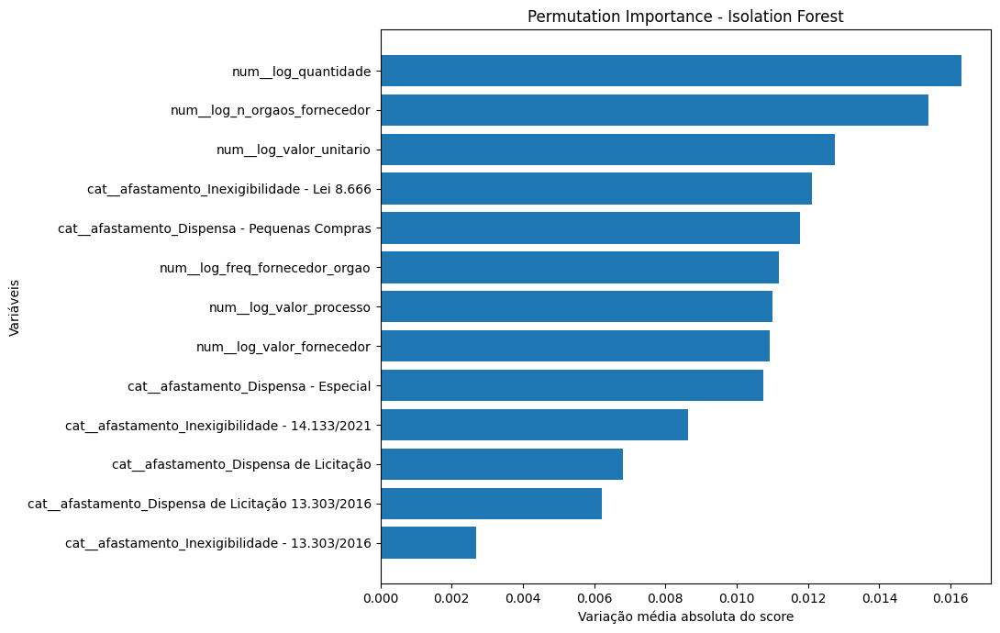


RESUMO DA ANÁLISE
------------------------------------------------------------
Variáveis analisadas: 13
Repetições por variável: 10

Variável de maior influência: num__log_quantidade
Importância: 0.016314

Análise concluída.


In [10]:
# --------------------------------------------------
# 1. IDENTIFICAR A MATRIZ E OS NOMES DAS VARIÁVEIS
# --------------------------------------------------

n_linhas, n_colunas = X.shape

# Tentar recuperar os nomes do ColumnTransformer
# Ajuste o nome caso seu objeto tenha outro identificador

if 'preprocessor' in globals():
    nomes_variaveis = preprocessor.get_feature_names_out()

elif 'preprocessador' in globals():
    nomes_variaveis = preprocessador.get_feature_names_out()

elif 'nomes_variaveis' in globals():
    nomes_variaveis = nomes_variaveis

else:
    nomes_variaveis = [
        f'variavel_{i}' for i in range(n_colunas)
    ]

nomes_variaveis = np.asarray(nomes_variaveis)

if len(nomes_variaveis) != n_colunas:
    nomes_variaveis = [
        f'variavel_{i}' for i in range(n_colunas)
    ]

print(f"Registros: {n_linhas:,}")
print(f"Variáveis: {n_colunas:,}")

# --------------------------------------------------
# 2. SCORE ORIGINAL DO MODELO
# --------------------------------------------------

# Scores maiores representam maior anomalia
score_original = -modelo_iforest.score_samples(X)

# --------------------------------------------------
# 3. CONFIGURAÇÕES DA PERMUTAÇÃO
# --------------------------------------------------

n_repeticoes = 10

rng = np.random.default_rng(42)

resultados = []

# --------------------------------------------------
# 4. PERMUTATION IMPORTANCE
# --------------------------------------------------

for i, nome in enumerate(nomes_variaveis):

    variacoes = []

    # Extrair somente a coluna analisada
    if issparse(X):
        valores_originais = X[:, i].toarray().ravel()
    else:
        valores_originais = np.asarray(X[:, i]).ravel()

    for repeticao in range(n_repeticoes):

        # Embaralhar os valores da coluna
        valores_permutados = rng.permutation(
            valores_originais
        )

        if issparse(X):

            # Trabalhar com uma cópia esparsa
            X_permutado = X.tolil(copy=True)

            X_permutado[:, i] = valores_permutados.reshape(-1, 1)

            X_permutado = X_permutado.tocsr()

        else:

            X_permutado = X.copy()
            X_permutado[:, i] = valores_permutados

        # Calcular novo score
        score_permutado = -modelo_iforest.score_samples(
            X_permutado
        )

        # Variação média absoluta dos scores
        variacao = np.mean(
            np.abs(score_permutado - score_original)
        )

        variacoes.append(variacao)

    resultados.append({
        'variavel': nome,
        'importancia_media': np.mean(variacoes),
        'desvio_importancia': np.std(variacoes)
    })

# --------------------------------------------------
# 5. ORGANIZAR RESULTADOS
# --------------------------------------------------

df_importancia_iforest = (
    pd.DataFrame(resultados)
    .sort_values(
        'importancia_media',
        ascending=False
    )
    .reset_index(drop=True)
)

# Ranking
df_importancia_iforest.insert(
    0,
    'ranking',
    range(1, len(df_importancia_iforest) + 1)
)

print("\nTOP 20 VARIÁVEIS MAIS INFLUENTES")
print("-" * 60)

display(
    df_importancia_iforest.head(20).round(6)
)

# --------------------------------------------------
# 6. GRÁFICO DAS 15 PRINCIPAIS VARIÁVEIS
# --------------------------------------------------

top_importancia = (
    df_importancia_iforest
    .head(15)
    .sort_values('importancia_media')
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_importancia['variavel'].astype(str),
    top_importancia['importancia_media']
)

plt.xlabel('Variação média absoluta do score')
plt.ylabel('Variáveis')
plt.title(
    'Permutation Importance - Isolation Forest'
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. RESUMO
# --------------------------------------------------

print("\nRESUMO DA ANÁLISE")
print("-" * 60)

print(f"Variáveis analisadas: {len(df_importancia_iforest)}")
print(f"Repetições por variável: {n_repeticoes}")

print(
    "\nVariável de maior influência:",
    df_importancia_iforest.iloc[0]['variavel']
)

print(
    "Importância:",
    round(
        df_importancia_iforest.iloc[0]['importancia_media'],
        6
    )
)

print("\nAnálise concluída.")


* Análise de Isolation Forest — Resultados Estatísticos

O Isolation Forest foi treinado com 300 árvores, contaminação de 5% e semente fixa (42). Sobre os 20.642 itens da base, o modelo classificou 1.033 como anômalos (5,00%) e 19.609 como normais. No nível dos processos, 698 dos 12.228 processos (5,71%) tiveram pelo menos um item sinalizado. A distribuição do percentual de itens sinalizados por processo apresentou média de 95,75%, mediana de 100%, máximo de 100% e mínimo de 3,60%; em 644 dos 698 processos com alguma sinalização, todos os itens foram classificados como anômalos. Esse padrão indica que, uma vez que um item de um processo é sinalizado, os demais itens do mesmo processo tendem a receber a mesma classificação, comportamento compatível com a presença de variáveis de nível de processo na matriz de atributos (valor do processo, valor acumulado por fornecedor, número de órgãos atendidos pelo fornecedor e frequência de processos por fornecedor e órgão), que se repetem para todos os itens do mesmo processo.

A análise de sensibilidade ao parâmetro `contamination` mostrou que a quantidade de itens sinalizados varia de forma monotônica com o critério adotado: com 3%, foram sinalizados 616 itens (2,98% da base) e 382 processos; com 4%, 826 itens (4,00%) e 534 processos; com 5%, 1.033 itens (5,00%) e 698 processos; com 6%, 1.237 itens (5,99%) e 844 processos; e com 7%, 1.445 itens (7,00%) e 971 processos. Os conjuntos identificados em cada limiar são aninhados: os 1.033 itens sinalizados com 5% estão integralmente contidos nos conjuntos sinalizados com 6% e 7% (Jaccard de 83,51% e 71,49%, respectivamente), e o conjunto de 3% (616 itens) está contido no de 5% (Jaccard de 59,63%), assim como o de 4% (826 itens, Jaccard de 79,96%). Esse comportamento é esperado, uma vez que o `contamination` define o limiar sobre a pontuação de anomalia e o modelo ordena os registros por essa pontuação. A quantidade de itens sinalizados, portanto, depende da parametrização adotada e não representa uma taxa de irregularidades comprovadas.

A análise de importância das variáveis por permutação (10 repetições por variável) indicou que as variáveis mais influentes sobre os escores de anomalia foram `log_quantidade` (0,0163), `log_n_orgaos_fornecedor` (0,0154), `log_valor_unitario` (0,0127), a categoria `Inexigibilidade - Lei 8.666` (0,0121) e a categoria `Dispensa - Pequenas Compras` (0,0118), seguidas por `log_freq_fornecedor_orgao` (0,0112), `log_valor_processo` (0,0110), `log_valor_fornecedor` (0,0109) e `Dispensa - Especial` (0,0107). As demais categorias de afastamento apresentaram importâncias inferiores a 0,009. Observa-se que as três primeiras posições são ocupadas por variáveis numéricas (quantidade, número de órgãos atendidos pelo fornecedor e valor unitário), o que indica que o modelo é mais sensível a características de quantidade e de concentração de fornecedor do que ao valor do processo ou ao valor acumulado por fornecedor. As importâncias obtidas representam uma medida de sensibilidade dos escores às variáveis e não devem ser interpretadas como relação causal. Além disso, como as variáveis categóricas foram permutadas individualmente, algumas combinações geradas podem não corresponder a perfis factíveis na base, o que deve ser considerado na interpretação.

## K-Means

* Análise de k

Formato da matriz X: (20642, 13)
Matriz esparsa: True
Testando K = 10...
Testando K = 11...
Testando K = 12...
Testando K = 13...
Testando K = 14...
Testando K = 15...
Testando K = 16...
Testando K = 17...
Testando K = 18...
Testando K = 19...
Testando K = 20...
Testando K = 21...
Testando K = 22...
Testando K = 23...
Testando K = 24...
Testando K = 25...
Testando K = 26...
Testando K = 27...
Testando K = 28...
Testando K = 29...
Testando K = 30...
Testando K = 31...
Testando K = 32...
Testando K = 33...
Testando K = 34...
Testando K = 35...
Testando K = 36...
Testando K = 37...
Testando K = 38...
Testando K = 39...
Testando K = 40...
Testando K = 41...
Testando K = 42...
Testando K = 43...
Testando K = 44...
Testando K = 45...
Testando K = 46...
Testando K = 47...
Testando K = 48...
Testando K = 49...
Testando K = 50...

Resultados dos testes:


,K,Inercia,Silhouette
0,10,33329.14,0.2196
1,11,32004.92,0.2006
2,12,30565.51,0.2063
3,13,29296.19,0.2271
4,14,28227.28,0.2197
5,15,27130.86,0.2271
6,16,26815.47,0.2288
7,17,25904.97,0.2353
8,18,25116.59,0.2361
9,19,24528.74,0.2224



Cinco melhores valores de K pelo Silhouette:


,K,Inercia,Silhouette
34,44,15497.38,0.2696
38,48,14567.45,0.2679
25,35,17589.58,0.2674
21,31,18810.94,0.2655
24,34,17739.40,0.2642


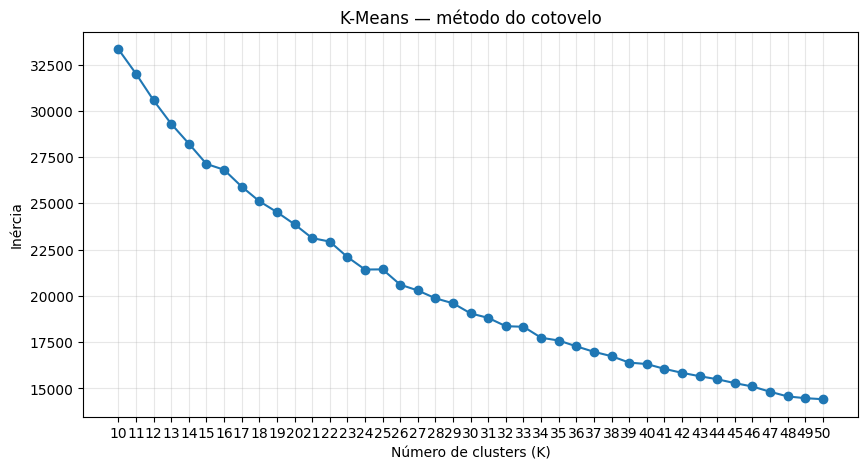

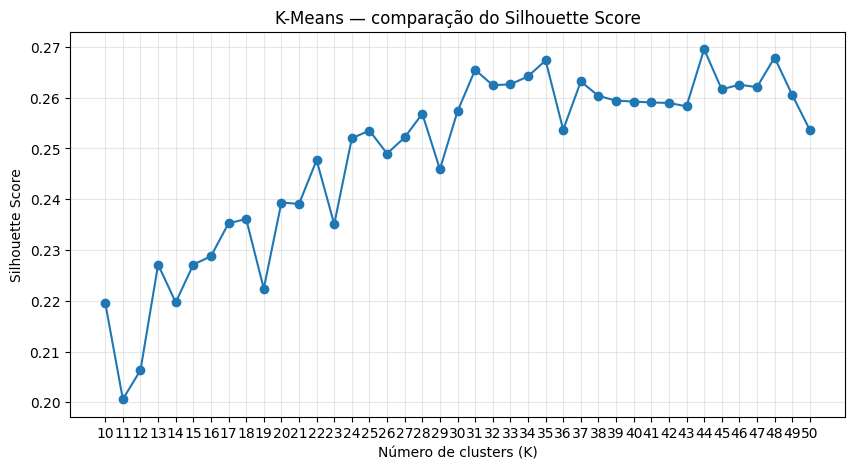

In [19]:
# Confirmar a matriz de entrada
print(f"Formato da matriz X: {X.shape}")
print(f"Matriz esparsa: {sparse.issparse(X)}")

# Faixa inicial de K: 10 a 50, de 1 em 1
valores_k = list(range(10, 51, 1))

# Selecionar uma amostra fixa para comparar os Silhouette Scores
rng = np.random.default_rng(42)
tamanho_amostra = min(2500, X.shape[0])
indices_amostra = np.sort(
    rng.choice(X.shape[0], size=tamanho_amostra, replace=False)
)

X_amostra = X[indices_amostra]

resultados_kmeans = []

for k in valores_k:
    print(f"Testando K = {k}...")

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5,
        max_iter=300,
        algorithm='lloyd'
    )

    # Ajustar o modelo em todos os registros
    modelo.fit(X)

    # Silhouette calculado na mesma amostra em todos os testes
    silhouette = silhouette_score(
        X_amostra,
        modelo.labels_[indices_amostra],
        metric='euclidean'
    )

    resultados_kmeans.append({
        'K': k,
        'Inercia': modelo.inertia_,
        'Silhouette': silhouette
    })

# Organizar os resultados
df_resultados_kmeans = pd.DataFrame(resultados_kmeans)

print("\nResultados dos testes:")
display(
    df_resultados_kmeans.round({
        'Inercia': 2,
        'Silhouette': 4
    })
)

print("\nCinco melhores valores de K pelo Silhouette:")
display(
    df_resultados_kmeans
    .sort_values('Silhouette', ascending=False)
    .head(5)
    .round({'Inercia': 2, 'Silhouette': 4})
)

# Gráfico 1: método do cotovelo
plt.figure(figsize=(10, 5))
plt.plot(
    df_resultados_kmeans['K'],
    df_resultados_kmeans['Inercia'],
    marker='o'
)
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia')
plt.title('K-Means — método do cotovelo')
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

# Gráfico 2: Silhouette Score
plt.figure(figsize=(10, 5))
plt.plot(
    df_resultados_kmeans['K'],
    df_resultados_kmeans['Silhouette'],
    marker='o'
)
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('K-Means — comparação do Silhouette Score')
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()


Refinar consulta entre k 30 e 49 e n_init

K=30 | n_init= 5 | Inércia=    19054.62 | Silhouette=0.2573
K=30 | n_init=10 | Inércia=    19054.62 | Silhouette=0.2573
K=30 | n_init=20 | Inércia=    19054.62 | Silhouette=0.2573
K=30 | n_init=50 | Inércia=    19054.62 | Silhouette=0.2573
K=31 | n_init= 5 | Inércia=    18810.94 | Silhouette=0.2655
K=31 | n_init=10 | Inércia=    18695.11 | Silhouette=0.2617
K=31 | n_init=20 | Inércia=    18695.11 | Silhouette=0.2617
K=31 | n_init=50 | Inércia=    18679.82 | Silhouette=0.2610
K=32 | n_init= 5 | Inércia=    18362.13 | Silhouette=0.2625
K=32 | n_init=10 | Inércia=    18362.13 | Silhouette=0.2625
K=32 | n_init=20 | Inércia=    18362.13 | Silhouette=0.2625
K=32 | n_init=50 | Inércia=    18362.13 | Silhouette=0.2625
K=33 | n_init= 5 | Inércia=    18333.34 | Silhouette=0.2626
K=33 | n_init=10 | Inércia=    18171.40 | Silhouette=0.2709
K=33 | n_init=20 | Inércia=    18077.93 | Silhouette=0.2705
K=33 | n_init=50 | Inércia=    18062.70 | Silhouette=0.2725
K=34 | n_init= 5 | Inércia=    17739.40 

n_init,5,10,20,50
K,,,,
30,0.2573,0.2573,0.2573,0.2573
31,0.2655,0.2617,0.2617,0.2610
32,0.2625,0.2625,0.2625,0.2625
33,0.2626,0.2709,0.2705,0.2725
34,0.2642,0.2642,0.2632,0.2632
35,0.2674,0.2673,0.2673,0.2706
36,0.2537,0.2537,0.2537,0.2666
37,0.2632,0.2632,0.2632,0.2663
38,0.2604,0.2604,0.2604,0.2584



Estabilidade do Silhouette por K:


,min,max,mean,std,amplitude
K,,,,,
30,0.2573,0.2573,0.2573,0.0000,0.0000
31,0.2610,0.2655,0.2625,0.0020,0.0045
32,0.2625,0.2625,0.2625,0.0000,0.0000
33,0.2626,0.2725,0.2691,0.0044,0.0099
34,0.2632,0.2642,0.2637,0.0006,0.0010
35,0.2673,0.2706,0.2681,0.0016,0.0033
36,0.2537,0.2666,0.2569,0.0065,0.0129
37,0.2632,0.2663,0.2640,0.0016,0.0031
38,0.2584,0.2604,0.2599,0.0010,0.0020


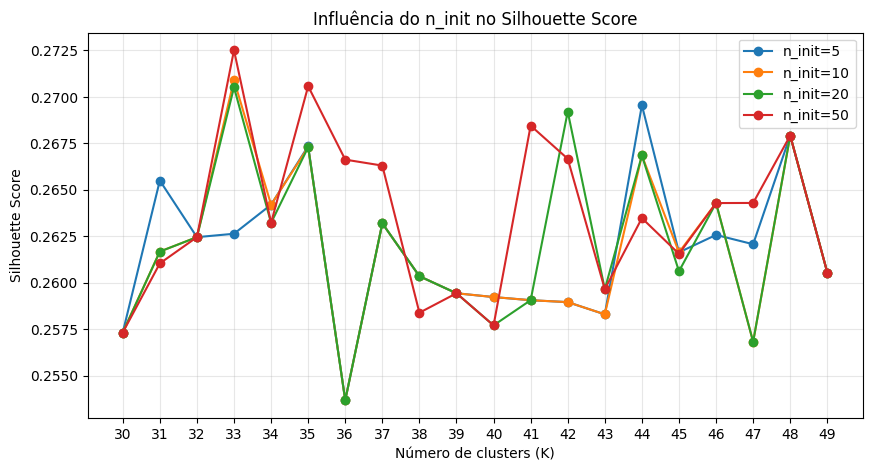

In [20]:
# Lista de Ks candidatos (ajuste conforme os melhores resultados)
ks_candidatos = list(range(30, 50, 1))

# Valores de n_init a testar
valores_n_init = [5, 10, 20, 50]

# Garantir amostra fixa (reutiliza a anterior se existir)
if 'indices_amostra' not in globals():
    rng = np.random.default_rng(42)
    indices_amostra = np.sort(
        rng.choice(X.shape[0], size=min(2500, X.shape[0]), replace=False)
    )
X_amostra = X[indices_amostra]

resultados_ninit = []

for k in ks_candidatos:
    for n_init in valores_n_init:
        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=n_init,
            max_iter=300,
            algorithm='lloyd'
        )
        modelo.fit(X)

        silhouette = silhouette_score(
            X_amostra,
            modelo.labels_[indices_amostra],
            metric='euclidean'
        )

        resultados_ninit.append({
            'K': k,
            'n_init': n_init,
            'Inercia': modelo.inertia_,
            'Silhouette': silhouette
        })

        print(f"K={k:2d} | n_init={n_init:2d} | Inércia={modelo.inertia_:12.2f} | Silhouette={silhouette:.4f}")

df_ninit = pd.DataFrame(resultados_ninit)

print("\nResumo por K:")
display(
    df_ninit.pivot_table(
        index='K',
        columns='n_init',
        values='Silhouette',
        aggfunc='mean'
    ).round(4)
)

# Calcular amplitude da variação do Silhouette por K
estabilidade = (
    df_ninit.groupby('K')['Silhouette']
    .agg(['min', 'max', 'mean', 'std'])
    .assign(amplitude=lambda x: x['max'] - x['min'])
    .round(4)
)
print("\nEstabilidade do Silhouette por K:")
display(estabilidade)

# Gráfico comparativo
plt.figure(figsize=(10, 5))
for n_init in valores_n_init:
    subset = df_ninit[df_ninit['n_init'] == n_init]
    plt.plot(subset['K'], subset['Silhouette'], marker='o', label=f'n_init={n_init}')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Influência do n_init no Silhouette Score')
plt.xticks(ks_candidatos)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

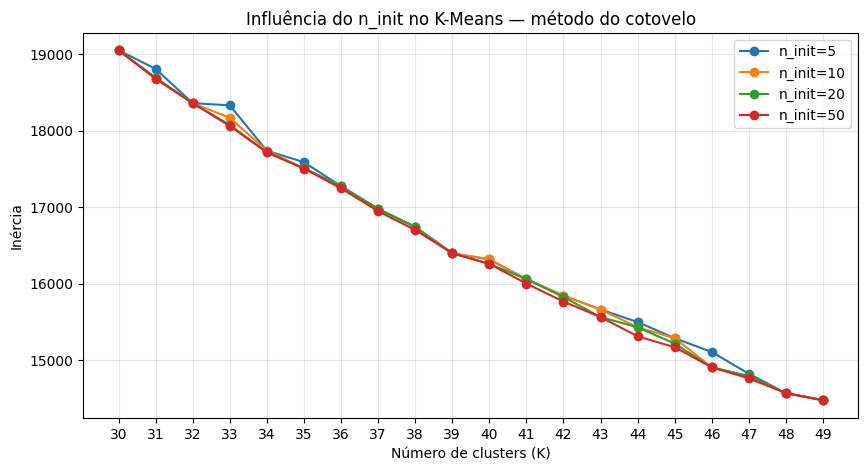

In [21]:
# Gráfico comparativo
plt.figure(figsize=(10, 5))
for n_init in valores_n_init:
    subset = df_ninit[df_ninit['n_init'] == n_init]
    plt.plot(subset['K'], subset['Inercia'], marker='o', label=f'n_init={n_init}')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inércia')
plt.title('Influência do n_init no K-Means — método do cotovelo')
plt.xticks(ks_candidatos)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Testes entre k = 33 e k = 48 (n_init = 50)

In [24]:
# Conversão apenas para as métricas que exigem matriz densa
X_dense = X.toarray() if hasattr(X, "toarray") else X

VALORES_K = [33, 48]
N_INIT = 50
RANDOM_STATE = 42

resultados = []
modelos = {}

for k in VALORES_K:

    modelo = KMeans(
        n_clusters=k,
        n_init=N_INIT,
        random_state=RANDOM_STATE
    )

    labels = modelo.fit_predict(X)
    modelos[k] = modelo

    tamanhos = pd.Series(labels).value_counts()

    n_registros = X.shape[0]


    resultados.append({
        "K": k,
        "Inércia": modelo.inertia_,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X_dense, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_dense, labels),
        "Menor cluster": tamanhos.min(),
        "Maior cluster": tamanhos.max(),
        "Clusters < 1%": (tamanhos < n_registros * 0.01).sum(),
        "Clusters < 5%": (tamanhos < n_registros * 0.05).sum()
    })

comparacao = pd.DataFrame(resultados).set_index("K")

print("COMPARAÇÃO DOS MODELOS")
display(comparacao.round(4))

for k, modelo in modelos.items():

    distribuicao = (
        pd.Series(modelo.labels_)
        .value_counts()
        .sort_index()
        .rename("Quantidade")
        .to_frame()
    )

    distribuicao["Percentual"] = (
        distribuicao["Quantidade"] / n_registros * 100
    )

    print(f"\nDISTRIBUIÇÃO DOS CLUSTERS — K={k}")
    display(distribuicao.round(2))


COMPARAÇÃO DOS MODELOS


,Inércia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Menor cluster,Maior cluster,Clusters < 1%,Clusters < 5%
K,,,,,,,,
33,18062.7000,0.2679,1.3101,2671.1520,130,1394,1,29
48,14567.4517,0.2696,1.2570,2358.5082,120,1147,6,47



DISTRIBUIÇÃO DOS CLUSTERS — K=33


,Quantidade,Percentual
0,352,1.71
1,1394,6.75
2,895,4.34
3,710,3.44
4,424,2.05
5,1227,5.94
6,1130,5.47
7,1276,6.18
8,470,2.28
9,598,2.90



DISTRIBUIÇÃO DOS CLUSTERS — K=48


,Quantidade,Percentual
0,328,1.59
1,656,3.18
2,419,2.03
3,240,1.16
4,543,2.63
5,646,3.13
6,886,4.29
7,298,1.44
8,586,2.84
9,837,4.05


* Analisar n_init para k = 48

In [27]:
# ------------------------------------------------------------
# 1. PREPARAÇÃO
# ------------------------------------------------------------

# Conversão apenas para as métricas que exigem matriz densa
X_dense = X.toarray() if hasattr(X, "toarray") else X

K = 48
VALORES_N_INIT = [5, 50]
RANDOM_STATE = 42

resultados = []
modelos_n_init = {}
distribuicoes = {}

n_registros = X.shape[0]

# ------------------------------------------------------------
# 2. EXECUÇÃO DOS MODELOS
# ------------------------------------------------------------

for n_init in VALORES_N_INIT:

    print(f"Executando K={K} | n_init={n_init}")

    modelo = KMeans(
        n_clusters=K,
        n_init=n_init,
        random_state=RANDOM_STATE
    )

    labels = modelo.fit_predict(X)

    modelos_n_init[n_init] = modelo

    tamanhos = pd.Series(labels).value_counts()

    distribuicoes[n_init] = tamanhos

    resultados.append({
        "n_init": n_init,
        "Inércia": modelo.inertia_,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(
            X_dense, labels
        ),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_dense, labels
        ),
        "Menor cluster": tamanhos.min(),
        "Maior cluster": tamanhos.max(),
        "Clusters < 1%": (
            tamanhos < n_registros * 0.01
        ).sum(),
        "Clusters < 5%": (
            tamanhos < n_registros * 0.05
        ).sum()
    })

# ------------------------------------------------------------
# 3. COMPARAÇÃO DAS MÉTRICAS
# ------------------------------------------------------------

comparacao_n_init = (
    pd.DataFrame(resultados)
    .set_index("n_init")
)

print("\n" + "=" * 70)
print("COMPARAÇÃO DOS MODELOS — K=48")
print("=" * 70)

display(comparacao_n_init.round(4))

# ------------------------------------------------------------
# 4. COMPARAÇÃO DA DISTRIBUIÇÃO DOS CLUSTERS
# ------------------------------------------------------------

df_distribuicao = pd.DataFrame({
    "n_init=5": modelos_n_init[5].labels_,
    "n_init=50": modelos_n_init[50].labels_
})

distribuicao_5 = (
    df_distribuicao["n_init=5"]
    .value_counts()
    .sort_index()
)

distribuicao_50 = (
    df_distribuicao["n_init=50"]
    .value_counts()
    .sort_index()
)

distribuicao_comparada = pd.DataFrame({
    "n_init=5": distribuicao_5,
    "n_init=50": distribuicao_50
}).fillna(0).astype(int)

distribuicao_comparada["Diferença absoluta"] = (
    distribuicao_comparada["n_init=5"]
    - distribuicao_comparada["n_init=50"]
).abs()

print("\nDISTRIBUIÇÃO DOS CLUSTERS — K=48")

display(
    distribuicao_comparada.sort_values(
        "n_init=50"
    )
)

# ------------------------------------------------------------
# 5. CONCORDÂNCIA ENTRE AS CLASSIFICAÇÕES
# ------------------------------------------------------------

from sklearn.metrics import adjusted_rand_score

labels_5 = modelos_n_init[5].labels_
labels_50 = modelos_n_init[50].labels_

ari = adjusted_rand_score(
    labels_5,
    labels_50
)

print("\n" + "=" * 70)
print("ESTABILIDADE DAS CLASSIFICAÇÕES")
print("=" * 70)

print(f"Adjusted Rand Index (ARI): {ari:.6f}")

# ------------------------------------------------------------
# 6. VARIAÇÃO DAS MÉTRICAS
# ------------------------------------------------------------

print("\nVARIAÇÃO ENTRE N_INIT=5 E N_INIT=50")

for metrica in comparacao_n_init.columns:

    valor_5 = comparacao_n_init.loc[5, metrica]
    valor_50 = comparacao_n_init.loc[50, metrica]

    diferenca = valor_50 - valor_5

    print(
        f"{metrica}: "
        f"{valor_5:.4f} → {valor_50:.4f} "
        f"(variação: {diferenca:+.4f})"
    )

# ------------------------------------------------------------
# 7. CONCLUSÃO AUTOMÁTICA
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONCLUSÃO DO EXPERIMENTO")
print("=" * 70)

if ari >= 0.99:
    print(
        "As classificações são praticamente idênticas. "
        "O aumento de n_init não alterou significativamente "
        "a composição dos clusters."
    )

elif ari >= 0.90:
    print(
        "As classificações apresentam alta concordância, "
        "com pequenas diferenças na composição dos clusters."
    )

else:
    print(
        "Foram observadas diferenças relevantes entre "
        "as classificações obtidas com os dois valores de n_init."
    )

print("\nExperimento concluído.")


Executando K=48 | n_init=5
Executando K=48 | n_init=50

COMPARAÇÃO DOS MODELOS — K=48


,Inércia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Menor cluster,Maior cluster,Clusters < 1%,Clusters < 5%
n_init,,,,,,,,
5,14567.4517,0.2696,1.257,2358.5082,120,1147,6,47
50,14567.4517,0.2696,1.257,2358.5082,120,1147,6,47



DISTRIBUIÇÃO DOS CLUSTERS — K=48


,n_init=5,n_init=50,Diferença absoluta
20,120,120,0
37,136,136,0
29,186,186,0
47,192,192,0
19,197,197,0
23,198,198,0
32,207,207,0
33,216,216,0
10,231,231,0
3,240,240,0



ESTABILIDADE DAS CLASSIFICAÇÕES
Adjusted Rand Index (ARI): 1.000000

VARIAÇÃO ENTRE N_INIT=5 E N_INIT=50
Inércia: 14567.4517 → 14567.4517 (variação: +0.0000)
Silhouette: 0.2696 → 0.2696 (variação: +0.0000)
Davies-Bouldin: 1.2570 → 1.2570 (variação: +0.0000)
Calinski-Harabasz: 2358.5082 → 2358.5082 (variação: +0.0000)
Menor cluster: 120.0000 → 120.0000 (variação: +0.0000)
Maior cluster: 1147.0000 → 1147.0000 (variação: +0.0000)
Clusters < 1%: 6.0000 → 6.0000 (variação: +0.0000)
Clusters < 5%: 47.0000 → 47.0000 (variação: +0.0000)

CONCLUSÃO DO EXPERIMENTO
As classificações são praticamente idênticas. O aumento de n_init não alterou significativamente a composição dos clusters.

Experimento concluído.


* K-Means com K= 48 e n_init = 5

In [28]:
# Conferir se a matriz X corresponde aos registros do dataframe
if X.shape[0] != len(df_ml):
    raise ValueError(
        "A quantidade de registros de X é diferente da quantidade de linhas de df_ml."
    )

# Configurar e executar o K-Means
modelo_kmeans = KMeans(
    n_clusters=48,
    random_state=42,
    n_init=5,
    max_iter=300,
    algorithm='lloyd'
)

df_ml['cluster_kmeans'] = modelo_kmeans.fit_predict(X)

# Calcular a distância de cada registro ao centroide do próprio cluster
distancias_centroides = modelo_kmeans.transform(X)

df_ml['distancia_centroide_kmeans'] = distancias_centroides[
    np.arange(len(df_ml)),
    df_ml['cluster_kmeans'].to_numpy()
]

print('K-MEANS EXECUTADO COM SUCESSO')
print('-' * 45)
print(f'Total de registros: {len(df_ml):,}')
print(f'Quantidade de clusters: {modelo_kmeans.n_clusters}')
print(f'Inércia final: {modelo_kmeans.inertia_:.2f}')

# Quantidade de registros em cada cluster
print('\nQUANTIDADE DE REGISTROS POR CLUSTER')

contagem_clusters = (
    df_ml['cluster_kmeans']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .reset_index(name='Quantidade')
)

contagem_clusters['Percentual'] = (
    100 * contagem_clusters['Quantidade'] / len(df_ml)
).round(2)

display(contagem_clusters)

# Perfil inicial dos clusters
print('\nPERFIL INICIAL DOS CLUSTERS')

resumo_clusters = (
    df_ml.groupby('cluster_kmeans')
    .agg(
        total_itens=('cluster_kmeans', 'size'),
        mediana_valor_processo=('valor_processo', 'median'),
        mediana_valor_unitario=('valor_unitario', 'median'),
        mediana_quantidade=('quantidade', 'median'),
        fornecedores_distintos=('fornecedor', 'nunique'),
        unidades_contratantes=('unidade', 'nunique'),
        percentual_zscore_sinalizado=(
            'anomalia_zscore',
            lambda s: (
                100 * s.eq(True).sum() / s.notna().sum()
                if s.notna().any() else np.nan
            )
        )
    )
    .round(2)
    .reset_index()
    .rename(columns={'cluster_kmeans': 'Cluster'})
)

display(resumo_clusters)

# Dez registros mais distantes dos respectivos centroides
print('\n10 REGISTROS MAIS DISTANTES DOS CENTROIDES')

colunas_exibicao = [
    'idprocesso',
    'fornecedor',
    'unidade',
    'item',
    'valor_processo',
    'valor_unitario',
    'zscore_preco',
    'anomalia_zscore',
    'cluster_kmeans',
    'distancia_centroide_kmeans'
]

display(
    df_ml.nlargest(10, 'distancia_centroide_kmeans')[
        colunas_exibicao
    ].reset_index(drop=True)
)


K-MEANS EXECUTADO COM SUCESSO
---------------------------------------------
Total de registros: 20,642
Quantidade de clusters: 48
Inércia final: 14567.45

QUANTIDADE DE REGISTROS POR CLUSTER


,Cluster,Quantidade,Percentual
0,0,328,1.59
1,1,656,3.18
2,2,419,2.03
3,3,240,1.16
4,4,543,2.63
5,5,646,3.13
6,6,886,4.29
7,7,298,1.44
8,8,586,2.84
9,9,837,4.05



PERFIL INICIAL DOS CLUSTERS


,Cluster,total_itens,mediana_valor_processo,mediana_valor_unitario,mediana_quantidade,fornecedores_distintos,unidades_contratantes,percentual_zscore_sinalizado
0,0,328,1.131620e+04,66.31,3.5,20,10,5.08
1,1,656,1.000000e+05,80000.00,1.0,79,13,0.15
2,2,419,2.913792e+04,5.10,593.0,178,50,1.52
3,3,240,4.617600e+04,559.98,3.0,8,50,4.55
4,4,543,3.673380e+03,850.00,1.0,295,53,0.87
5,5,646,2.210382e+04,6180.00,1.0,21,73,0.94
6,6,886,1.182900e+04,1200.00,1.0,450,70,2.92
7,7,298,1.196950e+06,4.22,20591.0,17,6,0.00
8,8,586,9.794016e+05,765845.86,1.0,234,38,2.25
9,9,837,8.820000e+03,4200.00,1.0,572,57,0.95



10 REGISTROS MAIS DISTANTES DOS CENTROIDES


,idprocesso,fornecedor,unidade,item,valor_processo,valor_unitario,zscore_preco,anomalia_zscore,cluster_kmeans,distancia_centroide_kmeans
0,1573,CAIXA ECONOMICA FEDERAL (MATRIZ),SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,0.01,0.01,-0.325504,False,9,3.187800
1,1455,BANCO DO BRASIL S/A,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,0.01,0.01,NaN,<NA>,9,3.107296
2,1445,BANCO DO BRASIL S/A,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,0.10,0.10,-0.325504,False,9,3.079004
3,4254,RIOCARD TECNOLOGIA DA INFORMAÇÃO S/A,FET - FUNDO ESTADUAL DE TRANSPORTES,DESPESAS COM TARIFAS - DESCRICAO: DESPESAS COM...,0.01,0.01,-0.729116,False,4,2.772026
4,6145,AGUAS DO RIO 1 SPE S.A,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,0.01,0.01,-0.231612,False,22,2.719617
5,5060,EMPRESA BRASILEIRA DE CORREIOS E TELÉGRAFOS,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,SERVICOS POSTAIS E TELEMATICOS - DESCRIÇÃO: CO...,56669407.48,8.54,NaN,<NA>,19,2.707260
6,11984,OI S/A,AGENERSA - AG REGUL ENERGIA E SANEAMENTO DO ES...,SERVICOS DE TELEFONIA - DESCRIÇÃO: DDG - TRAFE...,22998.20,0.02,NaN,<NA>,21,2.685956
7,2799,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,LUVA PROCEDIMENTO DESCARTAVEL - TIPO: NAO ESTE...,4830946.10,0.28,NaN,<NA>,7,2.461641
8,1585,AGUAS DO PARAIBA SA,RIOPREVIDÊNCIA - FUNDO UNICO DE PREVIDENCIA DO...,JUROS E MULTAS - DESCRICAO: ATRASOS NO RECOLHI...,10.00,10.00,-1.283897,False,22,2.451378
9,4458,HARPIA EMBALAGENS E TECNOLOGIA GRÁFICA LTDA EPP,CENTRAL - COMP EST DE ENGENH DE TRANSPORTES E ...,SERVICOS DE IMPRESSAO CORPORATIVA - DESCRICAO:...,33600.00,0.14,NaN,<NA>,15,2.256809


### Teste de sensibilidade

In [29]:
# ============================================================================
# Critérios: desvio-padrão, IQR, MAD e percentil 95
# Os limites são calculados separadamente dentro de cada cluster.
# ============================================================================

# Conferências iniciais
coluna_distancia = 'distancia_centroide_kmeans'
coluna_cluster = 'cluster_kmeans'

if coluna_distancia not in df_ml.columns or coluna_cluster not in df_ml.columns:
    raise ValueError("Execute primeiro a modelagem K-Means.")

if df_ml[coluna_distancia].isna().any():
    raise ValueError("Existem distâncias ausentes.")

# Criar cópia para preservar a base original
df_sensibilidade = df_ml.copy()

# Colunas de classificação
metodos = [
    'outlier_dp',
    'outlier_iqr',
    'outlier_mad',
    'outlier_p95'
]

for coluna in metodos:
    df_sensibilidade[coluna] = False

limites_clusters = []

# Calcular os limites individualmente por cluster
for cluster, grupo in df_sensibilidade.groupby(coluna_cluster):

    dist = grupo[coluna_distancia].astype(float)

    # 1. Desvio-padrão: média + 2 desvios-padrão
    media = dist.mean()
    desvio = dist.std(ddof=0)
    limite_dp = media + (2 * desvio)

    # 2. IQR: Q3 + 1,5 vezes o intervalo interquartil
    q1 = dist.quantile(0.25)
    q3 = dist.quantile(0.75)
    iqr = q3 - q1
    limite_iqr = q3 + (1.5 * iqr)

    # 3. MAD ajustado: mediana + 3 * 1,4826 * MAD
    mediana = dist.median()
    mad = (dist - mediana).abs().median()
    limite_mad = mediana + (3 * 1.4826 * mad)

    # 4. Percentil 95: identifica os 5% superiores
    limite_p95 = dist.quantile(0.95)

    # Registrar os limites
    limites_clusters.append({
        'Cluster': cluster,
        'Registros': len(grupo),
        'Média': media,
        'Desvio_Padrão': desvio,
        'Limite_DP': limite_dp,
        'Mediana': mediana,
        'MAD': mad,
        'Limite_MAD': limite_mad,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Limite_IQR': limite_iqr,
        'Limite_P95': limite_p95
    })

    # Classificar os registros acima de cada limite
    idx = grupo.index

    df_sensibilidade.loc[idx, 'outlier_dp'] = dist > limite_dp
    df_sensibilidade.loc[idx, 'outlier_iqr'] = dist > limite_iqr
    df_sensibilidade.loc[idx, 'outlier_mad'] = dist > limite_mad
    df_sensibilidade.loc[idx, 'outlier_p95'] = dist > limite_p95

# Tabela dos limites calculados por cluster
df_limites_clusters = pd.DataFrame(limites_clusters)

print("LIMITES DE CORTE POR CLUSTER")
display(
    df_limites_clusters.round(4)
)

# ============================================================================
# RESUMO GERAL DA SENSIBILIDADE
# ============================================================================

total_registros = len(df_sensibilidade)

resumo_sensibilidade = pd.DataFrame([
    {
        'Método': 'Desvio-padrão (média + 2 DP)',
        'Outliers': df_sensibilidade['outlier_dp'].sum()
    },
    {
        'Método': 'IQR (Q3 + 1,5 × IQR)',
        'Outliers': df_sensibilidade['outlier_iqr'].sum()
    },
    {
        'Método': 'MAD (mediana + 3 × 1,4826 × MAD)',
        'Outliers': df_sensibilidade['outlier_mad'].sum()
    },
    {
        'Método': 'Percentil 95 (5% superiores)',
        'Outliers': df_sensibilidade['outlier_p95'].sum()
    }
])

resumo_sensibilidade['Percentual'] = (
    100 * resumo_sensibilidade['Outliers'] / total_registros
).round(2)

print("\nCOMPARAÇÃO DOS MÉTODOS")
display(resumo_sensibilidade)

# ============================================================================
# COMPARAÇÃO POR CLUSTER
# ============================================================================

resumo_por_cluster = (
    df_sensibilidade
    .groupby('cluster_kmeans')
    .agg(
        total_registros=('cluster_kmeans', 'size'),
        outliers_dp=('outlier_dp', 'sum'),
        outliers_iqr=('outlier_iqr', 'sum'),
        outliers_mad=('outlier_mad', 'sum'),
        outliers_p95=('outlier_p95', 'sum')
    )
    .reset_index()
    .rename(columns={'cluster_kmeans': 'Cluster'})
)

print("\nOUTLIERS IDENTIFICADOS POR CLUSTER")
display(resumo_por_cluster)

# ============================================================================
# CONCORDÂNCIA ENTRE OS MÉTODOS
# ============================================================================

print("\nCONCORDÂNCIA ENTRE OS MÉTODOS")

df_sensibilidade['qtd_metodos_sinalizaram'] = (
    df_sensibilidade[metodos].sum(axis=1)
)

concordancia = (
    df_sensibilidade['qtd_metodos_sinalizaram']
    .value_counts()
    .sort_index()
    .rename_axis('Quantidade de métodos')
    .reset_index(name='Registros')
)

concordancia['Percentual'] = (
    100 * concordancia['Registros'] / total_registros
).round(2)

display(concordancia)

# Registros sinalizados por pelo menos um método
df_outliers_sensibilidade = df_sensibilidade[
    df_sensibilidade[metodos].any(axis=1)
].copy()

print(
    f"\nRegistros sinalizados por pelo menos um método: "
    f"{len(df_outliers_sensibilidade):,} "
    f"({100 * len(df_outliers_sensibilidade) / total_registros:.2f}%)"
)

print("\n10 MAIORES DISTÂNCIAS ENTRE OS REGISTROS SINALIZADOS")

colunas_resultado = [
    'idprocesso',
    'fornecedor',
    'unidade',
    'item',
    'cluster_kmeans',
    'distancia_centroide_kmeans'
] + metodos

display(
    df_outliers_sensibilidade
    .nlargest(10, 'distancia_centroide_kmeans')
    [colunas_resultado]
    .reset_index(drop=True)
)


LIMITES DE CORTE POR CLUSTER


,Cluster,Registros,Média,Desvio_Padrão,Limite_DP,Mediana,MAD,Limite_MAD,Q1,Q3,IQR,Limite_IQR,Limite_P95
0,0,328,0.8053,0.3517,1.5086,0.7095,0.2205,1.6903,0.5291,1.0235,0.4944,1.7651,1.4766
1,1,656,0.5263,0.2641,1.0545,0.4918,0.1378,1.1048,0.3671,0.6352,0.2682,1.0375,0.9438
2,2,419,0.8074,0.3454,1.4981,0.7008,0.1647,1.4332,0.5666,0.9489,0.3823,1.5223,1.4966
3,3,240,0.7953,0.3255,1.4462,0.7400,0.2243,1.7376,0.5440,1.0187,0.4747,1.7307,1.3587
4,4,543,0.6649,0.2878,1.2405,0.5979,0.1682,1.3462,0.4639,0.8059,0.3420,1.3188,1.1017
5,5,646,0.8432,0.2267,1.2967,0.8364,0.1431,1.4731,0.7004,0.9932,0.2928,1.4325,1.2142
6,6,886,0.6328,0.2110,1.0547,0.5970,0.1411,1.2246,0.4665,0.7612,0.2947,1.2033,1.0397
7,7,298,1.2800,0.3141,1.9082,1.2323,0.1986,2.1157,1.0445,1.4505,0.4060,2.0595,1.8840
8,8,586,0.6972,0.2929,1.2830,0.6877,0.1890,1.5283,0.4951,0.8721,0.3771,1.4377,1.2018
9,9,837,0.5638,0.2801,1.1240,0.5134,0.1537,1.1971,0.3674,0.6827,0.3153,1.1556,0.9724



COMPARAÇÃO DOS MÉTODOS


,Método,Outliers,Percentual
0,Desvio-padrão (média + 2 DP),774,3.75
1,"IQR (Q3 + 1,5 × IQR)",417,2.02
2,"MAD (mediana + 3 × 1,4826 × MAD)",399,1.93
3,Percentil 95 (5% superiores),1037,5.02



OUTLIERS IDENTIFICADOS POR CLUSTER


,Cluster,total_registros,outliers_dp,outliers_iqr,outliers_mad,outliers_p95
0,0,328,5,0,0,17
1,1,656,17,17,16,28
2,2,419,19,16,35,20
3,3,240,6,4,4,12
4,4,543,25,24,22,28
5,5,646,19,6,5,33
6,6,886,38,7,4,45
7,7,298,14,8,7,15
8,8,586,21,13,9,30
9,9,837,19,15,13,42



CONCORDÂNCIA ENTRE OS MÉTODOS


,Quantidade de métodos,Registros,Percentual
0,0,19538,94.65
1,1,328,1.59
2,2,346,1.68
3,3,113,0.55
4,4,317,1.54



Registros sinalizados por pelo menos um método: 1,104 (5.35%)

10 MAIORES DISTÂNCIAS ENTRE OS REGISTROS SINALIZADOS


,idprocesso,fornecedor,unidade,item,cluster_kmeans,distancia_centroide_kmeans,outlier_dp,outlier_iqr,outlier_mad,outlier_p95
0,1573,CAIXA ECONOMICA FEDERAL (MATRIZ),SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,9,3.187800,True,True,True,True
1,1455,BANCO DO BRASIL S/A,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,9,3.107296,True,True,True,True
2,1445,BANCO DO BRASIL S/A,SEFAZ - SECRETARIA DE ESTADO DE FAZENDA,SERVICOS BANCARIOS - DESCRIÇÃO: CONTRATACAO DE...,9,3.079004,True,True,True,True
3,4254,RIOCARD TECNOLOGIA DA INFORMAÇÃO S/A,FET - FUNDO ESTADUAL DE TRANSPORTES,DESPESAS COM TARIFAS - DESCRICAO: DESPESAS COM...,4,2.772026,True,True,True,True
4,6145,AGUAS DO RIO 1 SPE S.A,FUNARJ - FUND ANITA MANTUANO DE ARTES DO EST D...,SERVICO DE FORNECIMENTO DE AGUA - DESCRIÇÃO: C...,22,2.719617,True,True,True,True
5,5060,EMPRESA BRASILEIRA DE CORREIOS E TELÉGRAFOS,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,SERVICOS POSTAIS E TELEMATICOS - DESCRIÇÃO: CO...,19,2.707260,True,True,True,True
6,11984,OI S/A,AGENERSA - AG REGUL ENERGIA E SANEAMENTO DO ES...,SERVICOS DE TELEFONIA - DESCRIÇÃO: DDG - TRAFE...,21,2.685956,True,True,True,True
7,2799,MEDKA DISTRIBUIDORA HOSPITALAR LTDA,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,LUVA PROCEDIMENTO DESCARTAVEL - TIPO: NAO ESTE...,7,2.461641,True,True,True,True
8,1585,AGUAS DO PARAIBA SA,RIOPREVIDÊNCIA - FUNDO UNICO DE PREVIDENCIA DO...,JUROS E MULTAS - DESCRICAO: ATRASOS NO RECOLHI...,22,2.451378,True,True,True,True
9,4458,HARPIA EMBALAGENS E TECNOLOGIA GRÁFICA LTDA EPP,CENTRAL - COMP EST DE ENGENH DE TRANSPORTES E ...,SERVICOS DE IMPRESSAO CORPORATIVA - DESCRICAO:...,15,2.256809,True,True,True,True


Para a identificação de observações atípicas pelo K-Means, foi utilizada a distância de cada registro ao centroide do cluster ao qual foi atribuído. Como essa distância é calculada no espaço das variáveis transformadas e padronizadas, ela representa o grau de afastamento do registro em relação ao perfil multivariado de seu agrupamento.

Para estabelecer um critério único de sinalização, adotou-se o percentil 95 (P95) das distâncias em cada cluster. Assim, foram classificados como potencialmente anômalos os registros cuja distância ao centroide superou esse limite, correspondendo às observações mais afastadas dentro de cada agrupamento. A aplicação do critério resultou na sinalização de 1.037 registros, equivalentes a 5,02% da base analisada.

A escolha do P95 foi acompanhada por testes de sensibilidade com outros critérios estatísticos, como desvio-padrão, intervalo interquartil (IQR) e desvio absoluto mediano (MAD). Esses testes permitiram avaliar a variação das sinalizações conforme o método de definição do limite, mantendo-se o P95 como critério principal para a comparação com os demais métodos de detecção de anomalias. Ressalta-se que as sinalizações representam afastamentos estatísticos em relação aos agrupamentos identificados, não constituindo, isoladamente, evidência de irregularidade ou sobrepreço.

In [30]:
# 1. Preparar a matriz utilizada pelo K-Means
X_denso = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)

if X_denso.shape[0] != len(df_ml):
    raise ValueError("X e df_ml possuem quantidades diferentes de registros.")

# 2. Projetar os registros em duas dimensões
pca = PCA(
    n_components=2,
    svd_solver='randomized',
    random_state=42
)

coordenadas = pca.fit_transform(X_denso)

df_ml['pca_x'] = coordenadas[:, 0]
df_ml['pca_y'] = coordenadas[:, 1]

# 3. Calcular as coordenadas dos centroides na mesma projeção
centros = modelo_kmeans.cluster_centers_
centros_2d = pca.transform(centros)

# Centro global: média de todas as observações no espaço do modelo
centro_global = X_denso.mean(axis=0)
centro_global_2d = pca.transform(
    centro_global.reshape(1, -1)
)[0]

# Distância de cada centroide ao centro global, no espaço original
distancias_globais = np.linalg.norm(
    centros - centro_global,
    axis=1
)

# Quantidade de registros por cluster
n_clusters = modelo_kmeans.n_clusters

tamanhos = (
    df_ml['cluster_kmeans']
    .value_counts()
    .reindex(range(n_clusters), fill_value=0)
    .to_numpy()
)

# 4. Distância de cada registro ao próprio centroide
distancias = modelo_kmeans.transform(X_denso)
rotulos = df_ml['cluster_kmeans'].to_numpy()

distancias_proprias = distancias[
    np.arange(len(df_ml)), rotulos
]

df_ml['distancia_centroide_kmeans'] = distancias_proprias

# Marcar os 5% de registros mais distantes dos próprios centroides
limite = np.quantile(distancias_proprias, 0.95)
mask_distantes = distancias_proprias >= limite

# 5. Informações exibidas ao passar o mouse sobre os registros
colunas_hover = [
    c for c in [
        'idprocesso',
        'numero_processo',
        'fornecedor',
        'unidade',
        'item',
        'valor_processo',
        'valor_unitario',
        'cluster_kmeans',
        'distancia_centroide_kmeans'
    ]
    if c in df_ml.columns
]

nomes_legiveis = {
    'idprocesso': 'ID do processo',
    'numero_processo': 'Número do processo',
    'fornecedor': 'Fornecedor',
    'unidade': 'Unidade contratante',
    'item': 'Item',
    'valor_processo': 'Valor do processo',
    'valor_unitario': 'Valor unitário',
    'cluster_kmeans': 'Cluster',
    'distancia_centroide_kmeans': 'Distância ao próprio centroide'
}

dados_hover = df_ml[colunas_hover].astype(str).to_numpy()

linhas_hover = ''.join(
    f'{nomes_legiveis.get(c, c)}: %{{customdata[{i}]}}<br>'
    for i, c in enumerate(colunas_hover)
)

# 6. Construir o mapa interativo
fig = go.Figure()

# Todos os registros: pequenos e transparentes para reduzir sobreposição
fig.add_trace(go.Scatter(
    x=df_ml['pca_x'],
    y=df_ml['pca_y'],
    mode='markers',
    name='Registros',
    customdata=dados_hover,
    hovertemplate=linhas_hover + '<extra></extra>',
    marker=dict(
        size=4,
        opacity=0.28,
        color=df_ml['cluster_kmeans'],
        colorscale='Turbo',
        showscale=True,
        colorbar=dict(title='Cluster')
    )
))

# Registros mais distantes dos próprios centroides
fig.add_trace(go.Scatter(
    x=df_ml.loc[mask_distantes, 'pca_x'],
    y=df_ml.loc[mask_distantes, 'pca_y'],
    mode='markers',
    name='5% mais distantes',
    customdata=dados_hover[mask_distantes],
    hovertemplate=linhas_hover + '<extra></extra>',
    marker=dict(
        symbol='x',
        size=9,
        color='red',
        opacity=0.9
    )
))

# Centroides dos clusters
dados_centros = np.column_stack([
    np.arange(n_clusters),
    tamanhos,
    distancias_globais
])

fig.add_trace(go.Scatter(
    x=centros_2d[:, 0],
    y=centros_2d[:, 1],
    mode='markers+text',
    name='Centroides dos clusters',
    text=[f'C{i}' for i in range(n_clusters)],
    textposition='top center',
    customdata=dados_centros,
    hovertemplate=(
        '<b>Centroide C%{customdata[0]:.0f}</b><br>'
        'Registros: %{customdata[1]:.0f}<br>'
        'Distância ao centro global: %{customdata[2]:.3f}'
        '<extra></extra>'
    ),
    marker=dict(
        symbol='diamond',
        size=13,
        color='black',
        line=dict(color='white', width=1)
    )
))

# Centro global
fig.add_trace(go.Scatter(
    x=[centro_global_2d[0]],
    y=[centro_global_2d[1]],
    mode='markers+text',
    name='Centro global',
    text=['CENTRO GLOBAL'],
    textposition='bottom right',
    hovertemplate=(
        '<b>Centro global</b><br>'
        'Centro médio de todas as observações'
        '<extra></extra>'
    ),
    marker=dict(
        symbol='star',
        size=22,
        color='orange',
        line=dict(color='black', width=1.5)
    )
))

variancia = pca.explained_variance_ratio_.sum() * 100

fig.update_layout(
    title=(
        'Mapa 2D dos registros, centroides e centro global'
        f'<br><sup>PCA: {variancia:.2f}% da variância explicada '
        'pelos dois eixos</sup>'
    ),
    xaxis_title='Componente principal 1 (PCA)',
    yaxis_title='Componente principal 2 (PCA)',
    template='plotly_white',
    height=800,
    hovermode='closest',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='left',
        x=0
    )
)

fig.update_yaxes(
    scaleanchor="x",
    scaleratio=1
)

fig.show()

print(f"Registros: {len(df_ml):,}")
print(f"Clusters: {n_clusters}")
print(f"Variância explicada pelo PCA: {variancia:.2f}%")
print(f"Registros entre os 5% mais distantes: {mask_distantes.sum():,}")
print(f"Limite de distância para esse grupo: {limite:.4f}")


Registros: 20,642
Clusters: 48
Variância explicada pelo PCA: 50.67%
Registros entre os 5% mais distantes: 1,033
Limite de distância para esse grupo: 1.4103


* Criar anomalia_kmeans

In [31]:
# ============================================================
# SINALIZAÇÃO DE ANOMALIAS PELO K-MEANS — PERCENTIL 95
# ============================================================

# Cópia da base com os clusters já calculados
df_anomalias_kmeans = df_ml.copy()

# Identificar o cluster de cada registro
clusters = df_anomalias_kmeans['cluster_kmeans'].to_numpy()

# Recuperar a distância de cada registro ao seu próprio centroide
distancias = distancias_centroides[
    np.arange(len(df_anomalias_kmeans)), clusters
]

df_anomalias_kmeans['distancia_centroide_kmeans'] = distancias

# Calcular o P95 separadamente para cada cluster
limites_p95 = (
    df_anomalias_kmeans
    .groupby('cluster_kmeans')['distancia_centroide_kmeans']
    .quantile(0.95)
    .rename('limite_p95_kmeans')
)

df_anomalias_kmeans = df_anomalias_kmeans.merge(
    limites_p95,
    on='cluster_kmeans',
    how='left'
)

# Classificação única: acima do P95 = anomalia
df_anomalias_kmeans['anomalia_kmeans'] = (
    df_anomalias_kmeans['distancia_centroide_kmeans']
    > df_anomalias_kmeans['limite_p95_kmeans']
)

# Transferir a classificação e as informações para a base principal
df_ml['distancia_centroide_kmeans'] = (
    df_anomalias_kmeans['distancia_centroide_kmeans'].to_numpy()
)

df_ml['limite_p95_kmeans'] = (
    df_anomalias_kmeans['limite_p95_kmeans'].to_numpy()
)

df_ml['anomalia_kmeans'] = (
    df_anomalias_kmeans['anomalia_kmeans'].to_numpy()
)

# ============================================================
# RESUMO DOS RESULTADOS
# ============================================================

total = len(df_anomalias_kmeans)
anomalias = int(df_anomalias_kmeans['anomalia_kmeans'].sum())
normais = total - anomalias

print('=' * 65)
print('RESULTADO DA DETECÇÃO DE ANOMALIAS — K-MEANS (P95)')
print('=' * 65)

print(f'Total de itens:       {total:,}'.replace(',', '.'))
print(f'Itens normais:        {normais:,}'.replace(',', '.'))
print(f'Itens anômalos:       {anomalias:,}'.replace(',', '.'))
print(f'Percentual anômalo:   {anomalias / total * 100:.2f}%')

# ============================================================
# DISTRIBUIÇÃO DAS ANOMALIAS POR CLUSTER
# ============================================================

resumo_clusters = (
    df_anomalias_kmeans
    .groupby('cluster_kmeans')
    .agg(
        total_itens=('anomalia_kmeans', 'size'),
        anomalias=('anomalia_kmeans', 'sum'),
        limite_p95=('limite_p95_kmeans', 'first')
    )
)

resumo_clusters['percentual_anomalias'] = (
    resumo_clusters['anomalias'] /
    resumo_clusters['total_itens'] * 100
)

display(resumo_clusters.round(4))

# ============================================================
# EXTRAÇÃO DOS ITENS SINALIZADOS
# ============================================================

itens_anomalos_kmeans = (
    df_anomalias_kmeans[
        df_anomalias_kmeans['anomalia_kmeans']
    ]
    .sort_values(
        'distancia_centroide_kmeans',
        ascending=False
    )
    .copy()
)

print('\nItens sinalizados:', len(itens_anomalos_kmeans))

# Exibir colunas disponíveis para análise
colunas_desejadas = [
    'numero_processo',
    'FornecedorVencedor',
    'Unidade',
    'Item',
    'ValorProcesso',
    'ValorUnitario',
    'Quantidade',
    'cluster_kmeans',
    'distancia_centroide_kmeans',
    'limite_p95_kmeans',
    'anomalia_kmeans'
]

colunas_exibicao = [
    coluna for coluna in colunas_desejadas
    if coluna in itens_anomalos_kmeans.columns
]

display(itens_anomalos_kmeans[colunas_exibicao].head(30))


RESULTADO DA DETECÇÃO DE ANOMALIAS — K-MEANS (P95)
Total de itens:       20.642
Itens normais:        19.605
Itens anômalos:       1.037
Percentual anômalo:   5.02%


,total_itens,anomalias,limite_p95,percentual_anomalias
cluster_kmeans,,,,
0,328,17,1.4766,5.1829
1,656,28,0.9438,4.2683
2,419,20,1.4966,4.7733
3,240,12,1.3587,5.0000
4,543,28,1.1017,5.1565
5,646,33,1.2142,5.1084
6,886,45,1.0397,5.0790
7,298,15,1.8840,5.0336
8,586,30,1.2018,5.1195



Itens sinalizados: 1037


,numero_processo,cluster_kmeans,distancia_centroide_kmeans,limite_p95_kmeans,anomalia_kmeans
7959,SEI-040080/000128/2023,9,3.187800,0.972391,True
14098,SEI-040009/002108/2024,9,3.107296,0.972391,True
7884,SEI-040006/012589/2024,9,3.079004,0.972391,True
18784,SEI-100001/001851/2026,4,2.772026,1.101712,True
2977,SEI-180002/001345/22,22,2.719617,1.521475,True
18962,SEI-150016/002224/2026,19,2.707260,1.794058,True
13544,SEI-480002/000817/2023,21,2.685956,1.603866,True
8401,SEI-080002/000349/2024,7,2.461641,1.884050,True
858,SEI-040161/001031/2021,22,2.451378,1.521475,True
2453,SEI-100006/000001A/2023,15,2.256809,1.502218,True


## DBSCAN

* Definição dos parâmetros

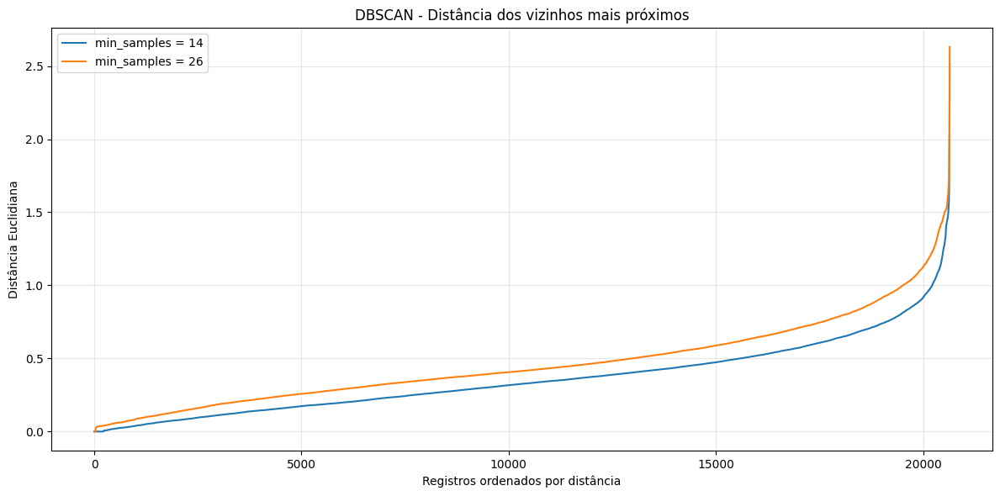

In [33]:
# Conferir a matriz utilizada
if X.shape[0] != len(df_ml):
    raise ValueError("X e df_ml possuem quantidades diferentes de registros.")

# Valores de min_samples que serão avaliados
valores_min_samples = [14,26]

# Calcular os vizinhos uma única vez, usando o maior valor
vizinhos = NearestNeighbors(
    n_neighbors=max(valores_min_samples),
    metric='euclidean',
    n_jobs=-1
)

vizinhos.fit(X)

distancias, _ = vizinhos.kneighbors(X)

# Construir gráfico das distâncias ordenadas
fig, ax = plt.subplots(figsize=(12, 6))

for min_samples in valores_min_samples:

    distancias_ordenadas = np.sort(
        distancias[:, min_samples - 1]
    )

    ax.plot(
        np.arange(1, len(distancias_ordenadas) + 1),
        distancias_ordenadas,
        label=f'min_samples = {min_samples}'
    )

ax.set_title('DBSCAN - Distância dos vizinhos mais próximos')
ax.set_xlabel('Registros ordenados por distância')
ax.set_ylabel('Distância Euclidiana')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:
# Conferência da matriz de entrada
if X.shape[0] != len(df_ml):
    raise ValueError("X e df_ml possuem quantidades diferentes de registros.")

# Parâmetros para investigação
valores_eps = [0.8, 1.0, 1.2]
valores_min_samples = [14,26]

resultados_dbscan = {}
resumo_dbscan = []

print("INICIANDO TESTES DO DBSCAN")
print("=" * 60)

for eps in valores_eps:

    for min_samples in valores_min_samples:

        print(f"Executando eps={eps} | min_samples={min_samples}...")

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean',
            n_jobs=-1
        )

        rotulos = modelo.fit_predict(X)

        # Armazenar os resultados para comparação posterior
        resultados_dbscan[(eps, min_samples)] = rotulos

        # Identificar ruídos e clusters
        quantidade_ruido = np.sum(rotulos == -1)
        percentual_ruido = quantidade_ruido / len(rotulos) * 100

        clusters_validos = rotulos[rotulos != -1]
        tamanhos_clusters = pd.Series(clusters_validos).value_counts()

        quantidade_clusters = len(tamanhos_clusters)

        if quantidade_clusters > 0:
            maior_cluster = tamanhos_clusters.max()
            menor_cluster = tamanhos_clusters.min()
            percentual_maior_cluster = maior_cluster / len(rotulos) * 100
        else:
            maior_cluster = 0
            menor_cluster = 0
            percentual_maior_cluster = 0

        resumo_dbscan.append({
            'eps': eps,
            'min_samples': min_samples,
            'quantidade_clusters': quantidade_clusters,
            'registros_ruido': quantidade_ruido,
            'percentual_ruido': percentual_ruido,
            'maior_cluster': maior_cluster,
            'percentual_maior_cluster': percentual_maior_cluster,
            'menor_cluster': menor_cluster
        })

# Consolidar resultados
df_resultados_dbscan = pd.DataFrame(resumo_dbscan)

print("\nRESUMO COMPARATIVO DOS PARÂMETROS")
display(
    df_resultados_dbscan
    .sort_values(['eps', 'min_samples'])
    .round(2)
    .reset_index(drop=True)
)


INICIANDO TESTES DO DBSCAN
Executando eps=0.8 | min_samples=14...
Executando eps=0.8 | min_samples=26...
Executando eps=1.0 | min_samples=14...
Executando eps=1.0 | min_samples=26...
Executando eps=1.2 | min_samples=14...
Executando eps=1.2 | min_samples=26...

RESUMO COMPARATIVO DOS PARÂMETROS


,eps,min_samples,quantidade_clusters,registros_ruido,percentual_ruido,maior_cluster,percentual_maior_cluster,menor_cluster
0,0.8,14,23,404,1.96,6257,30.31,10
1,0.8,26,20,1009,4.89,6095,29.53,33
2,1.0,14,13,112,0.54,6279,30.42,20
3,1.0,26,11,295,1.43,6271,30.38,27
4,1.2,14,8,58,0.28,6284,30.44,20
5,1.2,26,9,120,0.58,6279,30.42,27


EPS=0.74 | min_samples=14
EPS=0.74 | min_samples=26
EPS=0.75 | min_samples=14
EPS=0.75 | min_samples=26
EPS=0.76 | min_samples=14
EPS=0.76 | min_samples=26
EPS=0.77 | min_samples=14
EPS=0.77 | min_samples=26
EPS=0.78 | min_samples=14
EPS=0.78 | min_samples=26


,eps,min_samples,quantidade_clusters,registros_ruido,percentual_ruido,maior_cluster,percentual_maior_cluster,mediana_tamanho_cluster,clusters_com_50_ou_mais,registros_em_clusters_50_ou_mais
0,0.74,14,29,613,2.97,6230,30.18,62.0,16,19741
1,0.75,14,28,590,2.86,6248,30.27,65.5,16,19777
2,0.76,14,27,554,2.68,6251,30.28,62.0,15,19810
3,0.77,14,27,503,2.44,6254,30.30,62.0,15,19845
4,0.78,14,26,472,2.29,6257,30.31,71.0,15,19888
5,0.74,26,19,1445,7.00,5982,28.98,117.0,17,19130
6,0.75,26,19,1366,6.62,5998,29.06,117.0,17,19209
7,0.76,26,19,1267,6.14,6073,29.42,117.0,16,19264
8,0.77,26,20,1187,5.75,6081,29.46,114.5,16,19317
9,0.78,26,20,1123,5.44,6089,29.50,114.5,16,19365


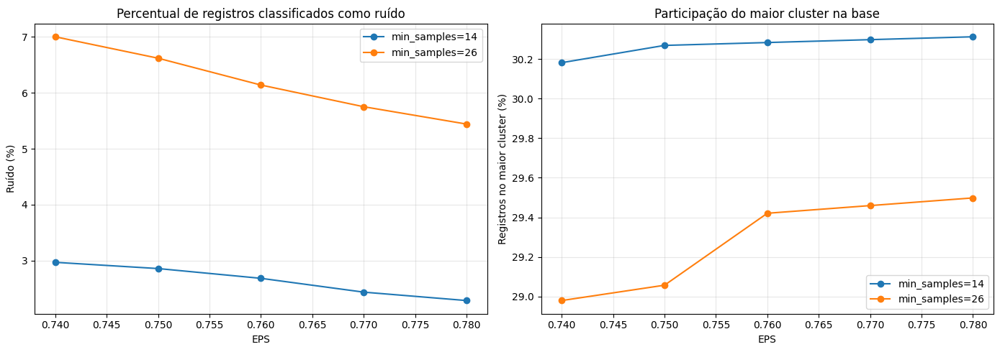

In [35]:
# Refinamento do intervalo de EPS
valores_eps = np.round(np.arange(0.74, 0.781, 0.01), 2)
valores_min_samples = [14, 26]

resultados_dbscan_refino = {}
resumo_refino = []

for eps in valores_eps:

    for min_samples in valores_min_samples:

        print(f"EPS={eps:.2f} | min_samples={min_samples}")

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean',
            n_jobs=-1
        )

        rotulos = modelo.fit_predict(X)

        resultados_dbscan_refino[(eps, min_samples)] = rotulos

        # Excluir ruídos para analisar os clusters
        tamanhos = pd.Series(
            rotulos[rotulos != -1]
        ).value_counts()

        quantidade_ruido = np.sum(rotulos == -1)

        if len(tamanhos) > 0:

            maior_cluster = tamanhos.max()
            mediana_cluster = tamanhos.median()

            clusters_maiores_50 = (tamanhos >= 50).sum()

            registros_clusters_maiores_50 = (
                tamanhos[tamanhos >= 50].sum()
            )

        else:
            maior_cluster = 0
            mediana_cluster = 0
            clusters_maiores_50 = 0
            registros_clusters_maiores_50 = 0

        resumo_refino.append({
            'eps': eps,
            'min_samples': min_samples,
            'quantidade_clusters': len(tamanhos),
            'registros_ruido': quantidade_ruido,
            'percentual_ruido': (
                quantidade_ruido / len(df_ml) * 100
            ),
            'maior_cluster': maior_cluster,
            'percentual_maior_cluster': (
                maior_cluster / len(df_ml) * 100
            ),
            'mediana_tamanho_cluster': mediana_cluster,
            'clusters_com_50_ou_mais': clusters_maiores_50,
            'registros_em_clusters_50_ou_mais': (
                registros_clusters_maiores_50
            )
        })

df_refino_dbscan = pd.DataFrame(resumo_refino)

display(
    df_refino_dbscan
    .round(2)
    .sort_values(['min_samples', 'eps'])
    .reset_index(drop=True)
)

# Gráfico de evolução do ruído e do maior cluster
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

for min_samples in valores_min_samples:

    dados = df_refino_dbscan[
        df_refino_dbscan['min_samples'] == min_samples
    ]

    eixos[0].plot(
        dados['eps'],
        dados['percentual_ruido'],
        marker='o',
        label=f'min_samples={min_samples}'
    )

    eixos[1].plot(
        dados['eps'],
        dados['percentual_maior_cluster'],
        marker='o',
        label=f'min_samples={min_samples}'
    )

eixos[0].set_title('Percentual de registros classificados como ruído')
eixos[0].set_xlabel('EPS')
eixos[0].set_ylabel('Ruído (%)')
eixos[0].grid(alpha=0.3)
eixos[0].legend()

eixos[1].set_title('Participação do maior cluster na base')
eixos[1].set_xlabel('EPS')
eixos[1].set_ylabel('Registros no maior cluster (%)')
eixos[1].grid(alpha=0.3)
eixos[1].legend()

plt.tight_layout()
plt.show()


,min_samples,eps,clusters,percentual_ruido,DBCV
0,26,0.74,19,7.0003,-0.1234
1,26,0.75,19,6.6176,-0.1676
2,26,0.76,19,6.1380,-0.1099
3,26,0.77,20,5.7504,-0.1545
4,26,0.78,20,5.4404,-0.1547


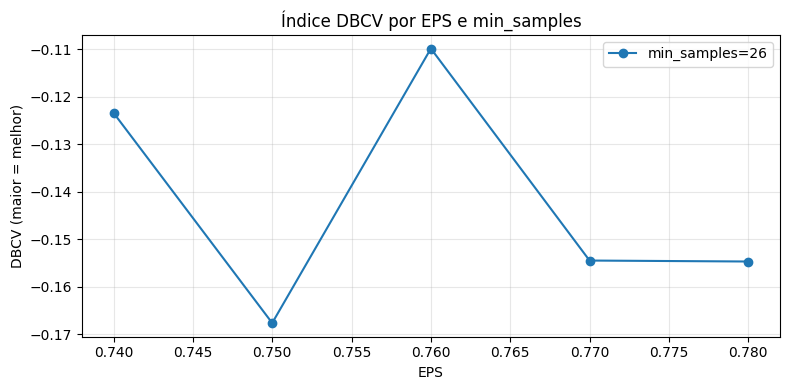

In [36]:
valores_min_samples = [26]
valores_eps = np.round(np.arange(0.74, 0.781, 0.01), 2)
eps = []

try:
    from hdbscan.validity import validity_index
except ImportError:
    !pip install -q hdbscan
    from hdbscan.validity import validity_index

# Converte X (mesmo se for matriz esparsa) para array denso float64
X_float = X.toarray().astype(np.float64) if sparse.issparse(X) else np.asarray(X, dtype=np.float64)

resultados_dbcv = []

for min_samples in valores_min_samples:
    for eps in valores_eps:
        rotulos = resultados_dbscan_refino[(eps, min_samples)]
        n_clusters = len(set(rotulos)) - (1 if -1 in rotulos else 0)

        score_dbcv = validity_index(X_float, rotulos, metric='euclidean') if n_clusters >= 2 else np.nan

        resultados_dbcv.append({
            'min_samples': min_samples,
            'eps': eps,
            'clusters': n_clusters,
            'percentual_ruido': np.mean(rotulos == -1) * 100,
            'DBCV': score_dbcv
        })

df_dbcv = pd.DataFrame(resultados_dbcv)

display(
    df_dbcv
    .round(4)
    .sort_values(['min_samples', 'eps'])
    .reset_index(drop=True)
)

# Gráfico do DBCV
plt.figure(figsize=(8, 4))
for min_samples in valores_min_samples:
    dados = df_dbcv[df_dbcv['min_samples'] == min_samples]
    plt.plot(dados['eps'], dados['DBCV'], marker='o', label=f'min_samples={min_samples}')

plt.title('Índice DBCV por EPS e min_samples')
plt.xlabel('EPS')
plt.ylabel('DBCV (maior = melhor)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


* anomalia_dbscan

In [37]:
# Configuração definitiva
modelo_dbscan = DBSCAN(
    eps=0.76,
    min_samples=26,
    metric='euclidean',
    n_jobs=-1
)

# Executar agrupamento
df_ml['cluster_dbscan'] = modelo_dbscan.fit_predict(X)

# Identificar registros classificados como ruído
df_ml['anomalia_dbscan'] = (
    df_ml['cluster_dbscan'] == -1
)

# Resumo geral
total_registros = len(df_ml)
total_ruido = df_ml['anomalia_dbscan'].sum()
total_clusters = df_ml.loc[
    df_ml['cluster_dbscan'] != -1,
    'cluster_dbscan'
].nunique()

print("=" * 60)
print("DBSCAN EXECUTADO COM SUCESSO")
print("=" * 60)

print(f"Total de registros: {total_registros:,}")
print(f"EPS: {modelo_dbscan.eps}")
print(f"Min_samples: {modelo_dbscan.min_samples}")
print(f"Quantidade de clusters: {total_clusters}")
print(f"Registros classificados como ruído: {total_ruido:,}")
print(f"Percentual de ruído: {total_ruido / total_registros * 100:.2f}%")

# Distribuição dos clusters
distribuicao = (
    df_ml['cluster_dbscan']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .reset_index(name='Quantidade')
)

distribuicao['Percentual'] = (
    distribuicao['Quantidade'] / total_registros * 100
)

print("\nDISTRIBUIÇÃO DOS CLUSTERS")
display(distribuicao.round(2))

# Conferência dos registros classificados como ruído
print("\nREGISTROS CLASSIFICADOS COMO RUÍDO")
display(
    df_ml[df_ml['anomalia_dbscan']]
    .head(10)
)


DBSCAN EXECUTADO COM SUCESSO
Total de registros: 20,642
EPS: 0.76
Min_samples: 26
Quantidade de clusters: 19
Registros classificados como ruído: 1,267
Percentual de ruído: 6.14%

DISTRIBUIÇÃO DOS CLUSTERS


,Cluster,Quantidade,Percentual
0,-1,1267,6.14
1,0,2661,12.89
2,1,2150,10.42
3,2,145,0.70
4,3,1741,8.43
5,4,100,0.48
6,5,66,0.32
7,6,34,0.16
8,7,81,0.39
9,8,6073,29.42



REGISTROS CLASSIFICADOS COMO RUÍDO


,iditens_processo,idprocesso,numero_processo,ano_processo,data_aprovacao,valor_processo,objeto,enquadramento,idorgao,unidade,...,score_anomalia_iforest,anomalia_iforest,cluster_kmeans,distancia_centroide_kmeans,pca_x,pca_y,limite_p95_kmeans,anomalia_kmeans,cluster_dbscan,anomalia_dbscan
45,341,181,270060/000626/2021,2023,2023-02-15,3944.78,AQUISIÇÃO DE TELAS DE POLIPROPILENO PARA A COR...,art 24inc II 8666/93,28,FUNESBOM - FUNDO ESPECIAL DO CORPO DE BOMBEIROS,...,0.521870,False,35,1.590194,-1.917279,-0.093049,1.004970,True,-1,True
138,617,437,E-02/002/464//2019,2023,2023-07-19,441718.20,OBJETO O GERENCIAMENTO DE ALOCAÇÃO DE MÃO DE O...,Lei 13303/2016,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,...,0.526104,False,44,1.330438,1.012130,0.749158,1.535581,False,-1,True
148,630,448,E-20/001.002722/2022,2023,2023-01-09,221675.62,CONTRATAÇÃO DOS SERVIÇOS DE ATUALIZAÇÃO E SUPO...,Art. 25 da Lei 8666/93,47,DPGE - DEFENSORIA PÚBLICA GERAL DO ESTADO,...,0.519151,False,23,0.915664,0.105412,0.779581,1.372341,False,-1,True
158,640,458,E-20/001.011505/2022,2023,2023-01-26,1158.00,AQUISIÇÃO DE EQUIPAMENTOS FOTOGRÁFICOS A FIM D...,Art. 24 da Lei 8666/93,47,DPGE - DEFENSORIA PÚBLICA GERAL DO ESTADO,...,0.508153,False,4,1.511651,-1.322563,-1.556614,1.101712,True,-1,True
170,654,463,L1SEI-210098/000688/2022,2023,2023-01-17,123300.00,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.539056,False,7,1.585643,-1.809371,3.051571,1.884050,False,-1,True
173,657,466,L3SEI-210098/000688/2022,2023,2023-01-17,92242.80,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.550360,False,7,1.745920,-1.975132,3.233272,1.884050,False,-1,True
174,658,467,L4SEI-210098/000688/2022,2023,2023-01-17,19644.30,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.550427,False,7,1.867282,-1.827432,2.633796,1.884050,False,-1,True
175,659,468,L5SEI-210098/000688/2022,2023,2023-01-17,640953.00,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.558591,True,7,1.989928,-2.138763,3.951190,1.884050,True,-1,True
176,660,469,L6SEI-210098/000688/2022,2023,2023-01-17,99496.08,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.543398,False,7,1.655575,-1.879038,3.103833,1.884050,False,-1,True
178,662,471,L8SEI-210098/000688/2022,2023,2023-01-17,120825.00,CONTRATAÇÃO EMERGENCIAL DE EMPRESA ESPECIALIZA...,"art. 24, IV, da Lei nº 8.666/1993.",20,SEPPENRJ - SECRETARIA DE ESTADO DE POLICIA PENAL,...,0.544074,False,7,1.657708,-1.899221,3.181790,1.884050,False,-1,True


* Resultados do DBSCAN

A aplicação do DBSCAN, utilizando os parâmetros `eps = 0,76` e `min_samples = 26`, identificou 19 agrupamentos e classificou 1.267 registros como ruído, correspondentes a 6,14% dos 20.642 registros analisados. Os resultados evidenciam a presença de agrupamentos com dimensões distintas, refletindo diferenças de densidade na distribuição das observações.

A distribuição dos registros apresentou concentração em poucos agrupamentos. Os dois maiores reuniram, respectivamente, 6.073 (29,42%) e 5.017 (24,30%) observações. Considerando os quatro maiores agrupamentos, a concentração alcançou 77,03% da base. Em contrapartida, os demais grupos apresentaram quantitativos menores, incluindo agrupamentos com menos de 100 registros. Essa distribuição demonstra que o algoritmo identificou regiões de diferentes densidades, sem impor previamente uma quantidade fixa de agrupamentos ou exigir que apresentassem tamanhos semelhantes.

Os 1.267 registros classificados como ruído não atenderam aos critérios de densidade necessários para integrar os agrupamentos identificados. Essa classificação representa um afastamento em relação às regiões densas encontradas pelo algoritmo, constituindo uma indicação de comportamento atípico segundo o critério de densidade utilizado. Entretanto, a condição de ruído não caracteriza, isoladamente, irregularidade na contratação ou inconsistência financeira, uma vez que registros legítimos também podem apresentar características pouco frequentes na base.

Dessa forma, os registros classificados como ruído foram considerados potenciais anomalias e incorporados à etapa de comparação com os demais métodos. Essa análise conjunta permite verificar quais observações receberam sinalizações coincidentes por diferentes abordagens, ampliando a capacidade de identificação de situações que mereçam investigação, sem atribuir às classificações estatísticas o caráter de comprovação de irregularidade.

## Comparação dos Métodos

In [38]:
# Lista de métodos para iterar
metodos = ['KMeans', 'IsolationForest', 'DBSCAN', 'Z-score']

# Construção do DataFrame de sinais usando as colunas consolidadas do df_ml
sinais = pd.DataFrame({
    'idprocesso': df_ml['idprocesso'].to_numpy(),

    'KMeans': (
        df_ml['anomalia_kmeans']
        .fillna(False)
        .astype(bool)
        .to_numpy()
    ),

    'IsolationForest': (
        df_ml['anomalia_iforest']
        .fillna(False)
        .astype(bool)
        .to_numpy()
    ),

    'DBSCAN': (
        df_ml['anomalia_dbscan']
        .fillna(False)
        .astype(bool)
        .to_numpy()
    ),

    'Z-score': (
        df_ml['anomalia_zscore']
        .fillna(False)
        .astype(bool)
        .to_numpy()
    )
})

# Quantidade de métodos que sinalizaram cada item
sinais['qtd_metodos'] = sinais[metodos].sum(axis=1)


# Combinações específicas entre os métodos
print('COMBINAÇÕES ENTRE OS MÉTODOS')

df_combinacoes = (
    sinais[sinais['qtd_metodos'] > 0]
    .groupby(metodos, as_index=False)
    .agg(
        itens=('idprocesso', 'size'),
        processos=('idprocesso', 'nunique')
    )
)

df_combinacoes['qtd_metodos'] = (
    df_combinacoes[metodos].sum(axis=1)
)

# Cria a string com os nomes dos métodos
df_combinacoes['metodos_sinalizadores'] = (
    df_combinacoes.apply(
        lambda linha: ' + '.join(
            metodo for metodo in metodos
            if linha[metodo]
        ),
        axis=1
    )
)

# Organiza a visualização
df_combinacoes = (
    df_combinacoes[
        ['metodos_sinalizadores', 'qtd_metodos', 'itens', 'processos']
    ]
    .sort_values(
        ['qtd_metodos', 'itens'],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(df_combinacoes)



# Concordância entre os métodos
print('RESUMO DA CONCORDÂNCIA')

total_processos = df_ml['idprocesso'].nunique()

resultados_concordancia = []

for minimo_metodos in range(1, 5):
    selecionados = sinais[
        sinais['qtd_metodos'] >= minimo_metodos
    ]

    processos = selecionados['idprocesso'].nunique()

    resultados_concordancia.append({
        'criterio': f'Pelo menos {minimo_metodos} método(s)',
        'itens_sinalizados': len(selecionados),
        'processos_sinalizados': processos,
        'percentual_processos': (processos / total_processos * 100)
    })

df_concordancia = pd.DataFrame(resultados_concordancia)
display(df_concordancia)



# Registros sem avaliação pelo Z-score
print('ANÁLISE DE DADOS AUSENTES NO Z-SCORE')

total_na_zscore = df_ml['zscore_preco'].isna().sum()

ruido_na_zscore = (
    (sinais['DBSCAN'])
    & (df_ml['zscore_preco'].isna().to_numpy())
).sum()

print(f'Registros sem Z-score calculável: {total_na_zscore:,}')
print(f'Registros de ruído do DBSCAN sem Z-score calculável: {ruido_na_zscore:,}')

COMBINAÇÕES ENTRE OS MÉTODOS


,metodos_sinalizadores,qtd_metodos,itens,processos
0,KMeans + IsolationForest + DBSCAN + Z-score,4,7,7
1,KMeans + IsolationForest + DBSCAN,3,101,82
2,IsolationForest + DBSCAN + Z-score,3,14,14
3,KMeans + DBSCAN + Z-score,3,7,7
4,KMeans + IsolationForest + Z-score,3,6,6
5,IsolationForest + DBSCAN,2,424,264
6,KMeans + DBSCAN,2,221,199
7,KMeans + IsolationForest,2,27,17
8,IsolationForest + Z-score,2,25,25
9,DBSCAN + Z-score,2,13,13


RESUMO DA CONCORDÂNCIA


,criterio,itens_sinalizados,processos_sinalizados,percentual_processos
0,Pelo menos 1 método(s),2710,1982,16.208701
1,Pelo menos 2 método(s),852,615,5.029441
2,Pelo menos 3 método(s),135,116,0.948642
3,Pelo menos 4 método(s),7,7,0.057246


ANÁLISE DE DADOS AUSENTES NO Z-SCORE
Registros sem Z-score calculável: 6,463
Registros de ruído do DBSCAN sem Z-score calculável: 390


## Exploração dos Processos Sinalizados

In [39]:
# ============================================================
# ANÁLISE FINANCEIRA DOS PROCESSOS SINALIZADOS
# ============================================================

# Coluna que contém o valor total do processo
coluna_valor = 'valor_processo'

# ------------------------------------------------------------
# 1. Consolidar a base na granularidade de processo
# ------------------------------------------------------------

base_processos = (
    df_ml[['idprocesso', coluna_valor]]
    .copy()
)

base_processos[coluna_valor] = pd.to_numeric(
    base_processos[coluna_valor],
    errors='coerce'
)

# Verificar se algum processo possui valores divergentes
divergencias = (
    base_processos
    .groupby('idprocesso')[coluna_valor]
    .nunique()
)

divergencias = divergencias[divergencias > 1]

if not divergencias.empty:
    raise ValueError(
        f'Existem {len(divergencias)} processos com valores divergentes. '
        'Verifique antes de consolidar.'
    )

# Cada processo deve aparecer apenas uma vez
base_processos = (
    base_processos
    .drop_duplicates(subset='idprocesso')
)

# Totais gerais
total_processos = base_processos['idprocesso'].nunique()
valor_total_base = base_processos[coluna_valor].sum()

# ------------------------------------------------------------
# 2. Calcular o impacto financeiro por nível de concordância
# ------------------------------------------------------------

resultados_financeiros = []

for minimo_metodos in range(1, 5):

    # Identificar os itens sinalizados pelo critério
    selecionados = sinais[
        sinais['qtd_metodos'] >= minimo_metodos
    ]

    # Identificar processos distintos
    ids_selecionados = selecionados[
        'idprocesso'
    ].drop_duplicates()

    # Recuperar o valor integral de cada processo
    processos_selecionados = base_processos[
        base_processos['idprocesso'].isin(ids_selecionados)
    ]

    qtd_processos = len(processos_selecionados)

    valor_selecionado = (
        processos_selecionados[coluna_valor].sum()
    )

    resultados_financeiros.append({
        'criterio': f'Pelo menos {minimo_metodos} método(s)',
        'itens_sinalizados': len(selecionados),
        'processos_sinalizados': qtd_processos,
        'percentual_processos': (
            qtd_processos / total_processos * 100
        ),
        'valor_processos': valor_selecionado,
        'percentual_valor': (
            valor_selecionado / valor_total_base * 100
            if valor_total_base else 0
        )
    })

df_resultado_financeiro = pd.DataFrame(
    resultados_financeiros
)

# ------------------------------------------------------------
# 3. Apresentar os resultados
# ------------------------------------------------------------

print('=' * 75)
print('IMPACTO FINANCEIRO DOS PROCESSOS SINALIZADOS')
print('=' * 75)

print(f'Total de processos na base: {total_processos:,}')
print(f'Valor total da base: R$ {valor_total_base:,.2f}')

print('\nRESULTADOS POR NÍVEL DE CONCORDÂNCIA')

display(
    df_resultado_financeiro.style.format({
        'itens_sinalizados': '{:,.0f}',
        'processos_sinalizados': '{:,.0f}',
        'percentual_processos': '{:.2f}%',
        'valor_processos': 'R$ {:,.2f}',
        'percentual_valor': '{:.2f}%'
    })
)


IMPACTO FINANCEIRO DOS PROCESSOS SINALIZADOS
Total de processos na base: 12,228
Valor total da base: R$ 17,742,002,281.79

RESULTADOS POR NÍVEL DE CONCORDÂNCIA


,criterio,itens_sinalizados,processos_sinalizados,percentual_processos,valor_processos,percentual_valor
0,Pelo menos 1 método(s),"2,710","1,982",16.21%,"R$ 10,017,313,940.12",56.46%
1,Pelo menos 2 método(s),852,615,5.03%,"R$ 5,128,533,805.30",28.91%
2,Pelo menos 3 método(s),135,116,0.95%,"R$ 2,307,984,639.47",13.01%
3,Pelo menos 4 método(s),7,7,0.06%,"R$ 292,751,345.98",1.65%


* Comparação financeira

In [43]:
# ------------------------------------------------------------
# 1. VALIDAR COLUNAS NECESSÁRIAS
# ------------------------------------------------------------

colunas_necessarias = ['idprocesso', 'valor_processo']

faltantes = [
    coluna for coluna in colunas_necessarias
    if coluna not in df_ml.columns
]

if faltantes:
    raise ValueError(f'Colunas ausentes em df_ml: {faltantes}')

if len(sinais) != len(df_ml):
    raise ValueError(
        'O DataFrame sinais não possui o mesmo número de linhas de df_ml.'
    )

# ------------------------------------------------------------
# 2. CONSTRUIR BASE DE PROCESSOS ÚNICOS
# ------------------------------------------------------------

base_processos = df_ml[
    ['idprocesso', 'valor_processo']
].copy()

base_processos['valor_processo'] = pd.to_numeric(
    base_processos['valor_processo'],
    errors='coerce'
)

# Verificar se existe mais de um valor por processo
divergencias = (
    base_processos
    .groupby('idprocesso')['valor_processo']
    .nunique()
)

divergencias = divergencias[divergencias > 1]

print('=' * 75)
print('CONFERÊNCIA DOS VALORES DOS PROCESSOS')
print('=' * 75)

print(
    f'Processos com mais de um valor registrado: '
    f'{len(divergencias):,}'
)

# Utilizar o primeiro valor não nulo de cada processo
base_processos = (
    base_processos
    .groupby('idprocesso', as_index=False)
    .agg(
        valor_processo=(
            'valor_processo',
            'first'
        )
    )
)

# ------------------------------------------------------------
# 3. IDENTIFICAR PROCESSOS COM ITENS SINALIZADOS
# ------------------------------------------------------------

sinais_processo = sinais[
    ['idprocesso', 'qtd_metodos']
].copy()

# Quantidade de itens sinalizados por processo em cada critério
for minimo in range(1, 5):
    sinais_processo[f'sinal_{minimo}'] = (
        sinais_processo['qtd_metodos'] >= minimo
    )

sinais_processo = (
    sinais_processo
    .groupby('idprocesso', as_index=False)
    .agg({
        'sinal_1': 'max',
        'sinal_2': 'max',
        'sinal_3': 'max',
        'sinal_4': 'max'
    })
)

# Incorporar as sinalizações à base de processos
base_processos = base_processos.merge(
    sinais_processo,
    on='idprocesso',
    how='left'
)

colunas_sinais = [
    f'sinal_{minimo}' for minimo in range(1, 5)
]

base_processos[colunas_sinais] = (
    base_processos[colunas_sinais]
    .fillna(False)
    .astype(bool)
)

# ------------------------------------------------------------
# 4. MEDIANA GERAL E MEDIANAS POR CONCORDÂNCIA
# ------------------------------------------------------------

mediana_geral = base_processos[
    'valor_processo'
].median()

valor_total_base = base_processos[
    'valor_processo'
].sum()

total_processos = len(base_processos)

print('\n' + '=' * 75)
print('MEDIANA GERAL DOS PROCESSOS')
print('=' * 75)

print(f'Total de processos: {total_processos:,}')
print(f'Mediana geral: R$ {mediana_geral:,.2f}')
print(f'Valor total: R$ {valor_total_base:,.2f}')

resultados_mediana = []

for minimo in range(1, 5):

    grupo = base_processos[
        base_processos[f'sinal_{minimo}']
    ].copy()

    grupo = grupo.dropna(subset=['valor_processo'])

    mediana_grupo = grupo['valor_processo'].median()
    valor_grupo = grupo['valor_processo'].sum()

    resultados_mediana.append({
        'Concordância': f'Pelo menos {minimo} método(s)',
        'Processos': len(grupo),
        'Mediana': mediana_grupo,
        'Mediana geral': mediana_geral,
        'Diferença mediana (%)': (
            (mediana_grupo / mediana_geral - 1) * 100
            if mediana_geral else np.nan
        ),
        'Valor acumulado': valor_grupo,
        '% do valor da base': (
            valor_grupo / valor_total_base * 100
            if valor_total_base else np.nan
        )
    })

df_mediana = pd.DataFrame(resultados_mediana)

print('\nCOMPARAÇÃO DAS MEDIANAS E VALORES')

display(
    df_mediana.style.format({
        'Mediana': 'R$ {:,.2f}',
        'Mediana geral': 'R$ {:,.2f}',
        'Diferença mediana (%)': '{:.2f}%',
        'Valor acumulado': 'R$ {:,.2f}',
        '% do valor da base': '{:.2f}%'
    })
)

# ------------------------------------------------------------
# 5. CONCENTRAÇÃO NOS DEZ MAIORES PROCESSOS
# ------------------------------------------------------------

resultados_concentracao = []

for minimo in range(1, 5):

    grupo = base_processos[
        base_processos[f'sinal_{minimo}']
    ].dropna(subset=['valor_processo']).copy()

    grupo = grupo.sort_values(
        'valor_processo',
        ascending=False
    )

    valor_grupo = grupo['valor_processo'].sum()

    top10 = grupo.head(10)

    valor_top10 = top10['valor_processo'].sum()

    resultados_concentracao.append({
        'Concordância': f'Pelo menos {minimo} método(s)',
        'Processos': len(grupo),
        'Valor do grupo': valor_grupo,
        'Valor dos 10 maiores': valor_top10,
        'Participação dos 10 maiores (%)': (
            valor_top10 / valor_grupo * 100
            if valor_grupo else np.nan
        )
    })

df_concentracao = pd.DataFrame(resultados_concentracao)

print('\n' + '=' * 75)
print('CONCENTRAÇÃO FINANCEIRA — DEZ MAIORES PROCESSOS')
print('=' * 75)

display(
    df_concentracao.style.format({
        'Valor do grupo': 'R$ {:,.2f}',
        'Valor dos 10 maiores': 'R$ {:,.2f}',
        'Participação dos 10 maiores (%)': '{:.2f}%'
    })
)

# ------------------------------------------------------------
# 6. DEZ MAIORES PROCESSOS NÃO SINALIZADOS
# ------------------------------------------------------------

nao_sinalizados = base_processos[
    ~base_processos['sinal_1']
].copy()

nao_sinalizados = (
    nao_sinalizados
    .dropna(subset=['valor_processo'])
    .sort_values(
        'valor_processo',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

print('\n' + '=' * 75)
print('DEZ MAIORES PROCESSOS NÃO SINALIZADOS POR NENHUM MÉTODO')
print('=' * 75)

display(
    nao_sinalizados[
        ['idprocesso', 'valor_processo']
    ].style.format({
        'valor_processo': 'R$ {:,.2f}'
    })
)

# ------------------------------------------------------------
# 7. COMPARAÇÃO DA MEDIANA — PROCESSOS SINALIZADOS X GERAL
# ------------------------------------------------------------

print('\n' + '=' * 75)
print('SÍNTESE DA COMPARAÇÃO DAS MEDIANAS')
print('=' * 75)

for _, linha in df_mediana.iterrows():

    print(
        f"\n{linha['Concordância']}:"
        f"\n  Mediana dos processos: R$ {linha['Mediana']:,.2f}"
        f"\n  Mediana geral:         R$ {mediana_geral:,.2f}"
        f"\n  Diferença:             {linha['Diferença mediana (%)']:.2f}%"
    )


CONFERÊNCIA DOS VALORES DOS PROCESSOS
Processos com mais de um valor registrado: 0

MEDIANA GERAL DOS PROCESSOS
Total de processos: 12,228
Mediana geral: R$ 50,000.00
Valor total: R$ 17,742,002,281.79

COMPARAÇÃO DAS MEDIANAS E VALORES


,Concordância,Processos,Mediana,Mediana geral,Diferença mediana (%),Valor acumulado,% do valor da base
0,Pelo menos 1 método(s),1982,"R$ 101,427.60","R$ 50,000.00",102.86%,"R$ 10,017,313,940.12",56.46%
1,Pelo menos 2 método(s),615,"R$ 79,390.66","R$ 50,000.00",58.78%,"R$ 5,128,533,805.30",28.91%
2,Pelo menos 3 método(s),116,"R$ 400,760.60","R$ 50,000.00",701.52%,"R$ 2,307,984,639.47",13.01%
3,Pelo menos 4 método(s),7,"R$ 43,000,000.00","R$ 50,000.00",85900.00%,"R$ 292,751,345.98",1.65%



CONCENTRAÇÃO FINANCEIRA — DEZ MAIORES PROCESSOS


,Concordância,Processos,Valor do grupo,Valor dos 10 maiores,Participação dos 10 maiores (%)
0,Pelo menos 1 método(s),1982,"R$ 10,017,313,940.12","R$ 2,543,470,853.17",25.39%
1,Pelo menos 2 método(s),615,"R$ 5,128,533,805.30","R$ 2,309,972,623.92",45.04%
2,Pelo menos 3 método(s),116,"R$ 2,307,984,639.47","R$ 1,489,657,606.44",64.54%
3,Pelo menos 4 método(s),7,"R$ 292,751,345.98","R$ 292,751,345.98",100.00%



DEZ MAIORES PROCESSOS NÃO SINALIZADOS POR NENHUM MÉTODO


,idprocesso,valor_processo
0,5270,"R$ 105,077,465.13"
1,1073,"R$ 96,742,700.00"
2,1039,"R$ 83,414,636.00"
3,1394,"R$ 59,909,829.11"
4,11021,"R$ 57,974,032.64"
5,11027,"R$ 56,098,693.37"
6,11921,"R$ 53,902,724.02"
7,11923,"R$ 53,772,781.43"
8,4929,"R$ 50,388,660.00"
9,11887,"R$ 49,667,956.58"



SÍNTESE DA COMPARAÇÃO DAS MEDIANAS

Pelo menos 1 método(s):
  Mediana dos processos: R$ 101,427.60
  Mediana geral:         R$ 50,000.00
  Diferença:             102.86%

Pelo menos 2 método(s):
  Mediana dos processos: R$ 79,390.66
  Mediana geral:         R$ 50,000.00
  Diferença:             58.78%

Pelo menos 3 método(s):
  Mediana dos processos: R$ 400,760.60
  Mediana geral:         R$ 50,000.00
  Diferença:             701.52%

Pelo menos 4 método(s):
  Mediana dos processos: R$ 43,000,000.00
  Mediana geral:         R$ 50,000.00
  Diferença:             85900.00%


In [40]:
# CORREÇÃO: TRATAMENTO DAS COLUNAS BOOLEANAS
flags = ['anomalia_kmeans', 'anomalia_iforest', 'anomalia_dbscan', 'anomalia_zscore']
for f in flags:
    # Preenche nulos com False, converte para booleano e depois para inteiro (0/1)
    df_ml[f] = df_ml[f].fillna(False).astype(bool).astype(int)


# OS 6 ITENS SINALIZADOS PELOS 4 MÉTODOS
print("\n--- ITENS SINALIZADOS POR TODOS OS 4 MÉTODOS ---")
itens_4_metodos = df_ml[
    (df_ml['anomalia_kmeans'] == 1) &
    (df_ml['anomalia_iforest'] == 1) &
    (df_ml['anomalia_dbscan'] == 1) &
    (df_ml['anomalia_zscore'] == 1)
]

colunas_itens = ['numero_processo', 'unidade', 'fornecedor', 'item', 'valor_unitario', 'valor_processo']
colunas_itens = [c for c in colunas_itens if c in itens_4_metodos.columns]

display(
    itens_4_metodos[colunas_itens]
    .sort_values('valor_processo', ascending=False)
    .round(2)
)


# AGREGAÇÃO NO NÍVEL DE PROCESSO

print("\nPreparando a visão de processos...")

# Agrupamos por processo. Se qualquer item do processo for 1, o processo é 1.
proc_consenso = df_ml.groupby('idprocesso').agg({
    'numero_processo': 'first',
    'unidade': 'first',
    'fornecedor': 'first',
    'valor_processo': 'max',
    'anomalia_kmeans': 'max',
    'anomalia_iforest': 'max',
    'anomalia_dbscan': 'max',
    'anomalia_zscore': 'max'
}).reset_index()

# Calcula quantos métodos sinalizaram o processo
proc_consenso['qtd_metodos'] = proc_consenso[flags].sum(axis=1)

# Cria a string com os nomes dos métodos
def formatar_metodos(row):
    metodos = []
    if row['anomalia_kmeans'] == 1: metodos.append('K-Means')
    if row['anomalia_iforest'] == 1: metodos.append('Isolation Forest')
    if row['anomalia_dbscan'] == 1: metodos.append('DBSCAN')
    if row['anomalia_zscore'] == 1: metodos.append('Z-score')
    return " + ".join(metodos)

proc_consenso['metodos_sinalizadores'] = proc_consenso.apply(formatar_metodos, axis=1)


# TOP 20 PROCESSOS COM EXATAMENTE 3 MÉTODOS

print("\n--- TOP 20 PROCESSOS COM EXATAMENTE 3 MÉTODOS (MAIORES VALORES) ---")

top_3_metodos = proc_consenso[proc_consenso['qtd_metodos'] == 3].copy()

display(
    top_3_metodos[[
        'numero_processo', 'unidade', 'fornecedor',
        'valor_processo', 'metodos_sinalizadores'
    ]]
    .sort_values('valor_processo', ascending=False)
    .head(20)
    .round(2)
)


# TOP 20 PROCESSOS COM EXATAMENTE 2 MÉTODOS

print("\n--- TOP 20 PROCESSOS COM EXATAMENTE 2 MÉTODOS (MAIORES VALORES) ---")

top_2_metodos = proc_consenso[proc_consenso['qtd_metodos'] == 2].copy()

display(
    top_2_metodos[[
        'numero_processo', 'unidade', 'fornecedor',
        'valor_processo', 'metodos_sinalizadores'
    ]]
    .sort_values('valor_processo', ascending=False)
    .head(20)
    .round(2)
)


--- ITENS SINALIZADOS POR TODOS OS 4 MÉTODOS ---


,numero_processo,unidade,fornecedor,item,valor_unitario,valor_processo
19859,SEI-260006/000016/2026,UERJ - ADMINISTRACAO CENTRAL,UNIVERSIDADE DO ESTADO DO RIO DE JANEIRO,SERVICOS DE APOIO ADMINISTRATIVO-FINANCEIRO - ...,54500000.00,54500000.00
20404,SEI-330003/000613/2026,EMOP - EMPRESA DE OBRAS PÚBLICAS DO ESTADO DO RJ,34.551.839/0001-30,SERVICOS DE ENGENHARIA - DESCRIÇÃO: CONTRATAÇÃ...,48625672.99,48625672.99
20633,SEI330003/000613/2026,EMOP - EMPRESA DE OBRAS PÚBLICAS DO ESTADO DO RJ,34.551.839/0001-30,SERVICOS DE ENGENHARIA - DESCRIÇÃO: CONTRATAÇÃ...,48625672.99,48625672.99
16772,SEI-260006/000046/2025,UERJ - ADMINISTRACAO CENTRAL,UNIVERSIDADE DO ESTADO DO RIO DE JANEIRO,SERVICOS DE APOIO ADMINISTRATIVO-FINANCEIRO - ...,43000000.00,43000000.00
11538,SEI-260007/000217/2024,UERJ - ADMINISTRACAO CENTRAL,UNIVERSIDADE DO ESTADO DO RIO DE JANEIRO,SERVICOS DE APOIO ADMINISTRATIVO-FINANCEIRO - ...,39000000.00,39000000.00
3834,SEI-260007/000968/2023,UERJ - ADMINISTRACAO CENTRAL,LIGHT SERVICOS DE ELETRICIDADE SA,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,36000000.00,36000000.00
18187,SEI-020004/000711/2025,CEASA-RJ - CENTRAIS DE ABASTECIMENTO DO ESTADO...,LIGHT SERVICOS DE ELETRICIDADE SA,FORNECIMENTO DE ENERGIA ELETRICA - DESCRIÇÃO: ...,23000000.00,23000000.00



Preparando a visão de processos...

--- TOP 20 PROCESSOS COM EXATAMENTE 3 MÉTODOS (MAIORES VALORES) ---


,numero_processo,unidade,fornecedor,valor_processo,metodos_sinalizadores
5060,SEI-150016/022951/2024,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,COMÉRCIO IMPORTAÇÃO E EXPORTAÇÃO 3 IRMÃOS LTDA,2.671372e+08,K-Means + DBSCAN + Z-score
2524,SEI-080001/002641/G/2022,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,2.337506e+08,K-Means + Isolation Forest + DBSCAN
2702,SEI-080001/025088/2021,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,2.137419e+08,K-Means + Isolation Forest + DBSCAN
2705,SEI-080001/025088C/2021,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,1.919241e+08,K-Means + Isolation Forest + DBSCAN
2620,SEI-080001/015269B/2023,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO D`OR DE GESTÃO DE SAÚDE PÚBLICA,1.193165e+08,K-Means + DBSCAN + Z-score
5070,SEI-150016/070590A/2025,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,EMPRESA BRASILEIRA DE CORREIOS E TELEGRAFOS,1.074715e+08,K-Means + DBSCAN + Z-score
5071,SEI-150016/070590B/2025,DETRAN - DEPARTAMENTO DE TRÂNSITO DO ESTADO DO RJ,EMPRESA BRASILEIRA DE CORREIOS E TELÉGRAFOS,1.074715e+08,K-Means + DBSCAN + Z-score
2712,SEI-080001/025266C/2021,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO DE DESENVOLVIMENTO ENSINO E ASSISTÊN...,9.691687e+07,K-Means + Isolation Forest + DBSCAN
2929,SEI-080002/001712/2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,TUISE REPRESENTAÇÃO COMERCIAL LTDA,8.040135e+07,K-Means + Isolation Forest + Z-score
2982,SEI-080002/003055/2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,TUISE REPRESENTAÇÃO COMERCIAL LTDA,7.152600e+07,K-Means + Isolation Forest + Z-score



--- TOP 20 PROCESSOS COM EXATAMENTE 2 MÉTODOS (MAIORES VALORES) ---


,numero_processo,unidade,fornecedor,valor_processo,metodos_sinalizadores
4805,SEI-140001/078164/2024,SETRANS - SECRETARIA DE ESTADO DE TRANSPORTES,PY13 PARTICIPACOES S.A,6.600000e+08,K-Means + DBSCAN
8526,SEI-260005/006791/2026,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,SERVIÇO NACIONAL DE APRENDIZAGEM COMERCIAL - S...,2.092889e+08,K-Means + DBSCAN
1401,SEI-030029/015972/2023,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EDITORA ROCCO LTDA,1.780971e+08,Isolation Forest + DBSCAN
2617,SEI-080001/015269-D/2023,FES - FUNDO ESTADUAL DE SAÚDE,INSTITUTO D`OR DE GESTÃO DE SAÚDE PÚBLICA,1.292448e+08,K-Means + DBSCAN
1045,SEI-030001/069533/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,EUREKA SOLUCOES PEDAGOGICAS LTDA,1.259498e+08,K-Means + Isolation Forest
8525,SEI-260005/006727/2026,FAETEC - CCF - FUND DE APOIO À ESCOLA TÉCNICA ...,SERVIÇO NACIONAL DE APRENDIZAGEM INDUSTRIAL,1.038960e+08,K-Means + DBSCAN
894,SEI-030001/004874/2024,SEEDUC - SECRETARIA DE ESTADO DE EDUCAÇÃO,"FUNDAÇÃO DE APOIO A PESQUISA, ENSINO E ASSISTE...",9.527613e+07,K-Means + DBSCAN
2588,SEI-080001/013025I/2023,FES - FUNDO ESTADUAL DE SAÚDE,UNIMED SÃO GONÇALO NITEROI SOC. COOP. SERV. ME...,5.454000e+07,Isolation Forest + Z-score
3639,SEI-080007/001775/2024,FSERJ - FUNDAÇÃO SAÚDE DO EST. DO RIO DE JANEIRO,ECO RIO COMERCIO E SERVIÇOS GERAIS LTDA,5.280375e+07,K-Means + Z-score
2566,SEI-080001/012128F/2023,FES - FUNDO ESTADUAL DE SAÚDE,HOSPITAL E MATERNIDADE NEOMATER LTDA,4.899627e+07,Isolation Forest + Z-score


* Análise combinada dos métodos e impacto financeiro

A combinação dos quatro métodos de detecção de anomalias permitiu avaliar a convergência das sinalizações produzidas individualmente pelos algoritmos. Ao considerar os itens identificados por pelo menos um método, foram contabilizados 2.710 itens, associados a 1.982 processos, correspondendo a 16,21% do universo de processos da base. Ao exigir a concordância de pelo menos dois métodos, o conjunto passou a 852 itens, distribuídos em 615 processos (5,03% do universo), cujo valor integral acumulado alcançou R$ 5,13 bilhões, equivalente a 28,91% do valor total analisado.

Com o aumento do critério de concordância para pelo menos três métodos, foram identificados 135 itens, associados a 116 processos (0,95% do universo), que representam R\$ 2,31 bilhões, ou 13,01% do valor total da base. Na concordância simultânea dos quatro métodos, foram identificados sete itens, distribuídos em sete processos, totalizando R$ 292,75 milhões (1,65% do valor total analisado).

Essa análise conjunta permite estabelecer níveis distintos de prioridade para investigação, considerando a quantidade de métodos que sinalizaram cada item. Quanto maior a concordância entre os algoritmos, maior a convergência das indicações produzidas por abordagens distintas, embora isso não represente, isoladamente, comprovação de anomalia ou irregularidade. Ressalta-se ainda que os valores financeiros apresentados correspondem ao montante integral dos processos que contêm itens sinalizados, e não exclusivamente aos valores dos itens identificados pelos métodos.


## Criar tabela ml_resultados no Supabase

In [41]:
# Criação da tabela no Supabase
sql_criar_tabela = """
CREATE TABLE IF NOT EXISTS public.resultado_ml (

    idresultado_ml SERIAL PRIMARY KEY,

    -- Chave estrangeira para o item
    itens_processo_iditens_processo INTEGER NOT NULL UNIQUE
        REFERENCES public.itens_processo(iditens_processo)
        ON DELETE CASCADE,

    -- 1. Z-SCORE
    zscore_preco NUMERIC(18,6),
    anomalia_zscore BOOLEAN,

    -- 2. K-MEANS
    cluster_kmeans INTEGER,
    distancia_centroid_kmeans NUMERIC(18,6),
    limite_anomalia_kmeans NUMERIC(18,6),
    anomalia_kmeans BOOLEAN NOT NULL DEFAULT FALSE,

    -- 3. ISOLATION FOREST
    score_anomalia_iforest NUMERIC(18,6),
    anomalia_iforest BOOLEAN NOT NULL DEFAULT FALSE,

    -- 4. DBSCAN
    cluster_dbscan INTEGER,
    anomalia_dbscan BOOLEAN NOT NULL DEFAULT FALSE,

    -- 5. RESULTADO COMBINADO
    qtd_metodos_sinalizadores SMALLINT,
    metodos_sinalizadores TEXT,

    -- Auditoria
    data_execucao TIMESTAMPTZ NOT NULL DEFAULT NOW()
);
"""

# Executar criação e confirmar transação
with engine.begin() as conn:
    conn.execute(text(sql_criar_tabela))

    # Consultar estrutura criada
    resultado = conn.execute(text("""
        SELECT
            column_name,
            data_type,
            is_nullable
        FROM information_schema.columns
        WHERE table_schema = 'public'
          AND table_name = 'resultado_ml'
        ORDER BY ordinal_position;
    """))

    colunas = resultado.fetchall()

# Exibir confirmação
print("Tabela resultado_ml criada ou já existente no Supabase.")
print(f"Total de colunas: {len(colunas)}")

df_estrutura = pd.DataFrame(
    colunas,
    columns=['Coluna', 'Tipo de dado', 'Aceita NULL']
)

display(df_estrutura)

Tabela resultado_ml criada ou já existente no Supabase.
Total de colunas: 15


,Coluna,Tipo de dado,Aceita NULL
0,idresultado_ml,integer,NO
1,itens_processo_iditens_processo,integer,NO
2,zscore_preco,numeric,YES
3,anomalia_zscore,boolean,YES
4,cluster_kmeans,integer,YES
5,distancia_centroid_kmeans,numeric,YES
6,limite_anomalia_kmeans,numeric,YES
7,anomalia_kmeans,boolean,NO
8,score_anomalia_iforest,numeric,YES
9,anomalia_iforest,boolean,NO


## Salvar resultados no Supabase

In [42]:
# ============================================================
# GRAVAÇÃO DOS RESULTADOS DOS MODELOS NO SUPABASE
# ============================================================

# ------------------------------------------------------------
# 1. VALIDAR DATAFRAME E COLUNAS
# ------------------------------------------------------------

if 'df_ml' not in globals():
    raise NameError("O DataFrame df_ml não foi encontrado.")

# Ajustar estes nomes caso sejam diferentes no seu df_ml
coluna_distancia = 'distancia_centroide_kmeans'
coluna_limite = 'limite_p95_kmeans'

colunas_necessarias = [
    'iditens_processo',
    'zscore_preco',
    'anomalia_zscore',
    'cluster_kmeans',
    coluna_distancia,
    coluna_limite,
    'anomalia_kmeans',
    'score_anomalia_iforest',
    'anomalia_iforest',
    'cluster_dbscan',
    'anomalia_dbscan'
]

faltantes = [
    c for c in colunas_necessarias
    if c not in df_ml.columns
]

if faltantes:
    raise KeyError(
        f"Colunas ausentes no df_ml: {faltantes}. "
        "Verifique os nomes das variáveis produzidas pelos modelos."
    )

# ------------------------------------------------------------
# 2. MONTAR DATAFRAME FINAL
# ------------------------------------------------------------

df_resultados_ml = df_ml[colunas_necessarias].copy()

# Renomear para os nomes definitivos do banco
df_resultados_ml = df_resultados_ml.rename(columns={
    coluna_distancia: 'distancia_centroid_kmeans',
    coluna_limite: 'limite_anomalia_kmeans'
})

# Validar IDs
if df_resultados_ml['iditens_processo'].isna().any():
    raise ValueError("Existem IDs de itens nulos.")

df_resultados_ml['iditens_processo'] = pd.to_numeric(
    df_resultados_ml['iditens_processo'],
    errors='raise'
)

if not np.isfinite(
    df_resultados_ml['iditens_processo'].astype(float)
).all():
    raise ValueError("Existem IDs inválidos.")

if not (
    df_resultados_ml['iditens_processo'] % 1 == 0
).all():
    raise ValueError("Existem IDs que não são inteiros.")

df_resultados_ml['iditens_processo'] = (
    df_resultados_ml['iditens_processo'].astype('int64')
)

if df_resultados_ml['iditens_processo'].duplicated().any():
    raise ValueError(
        "Existem IDs de itens duplicados no df_ml. "
        "Verifique antes da gravação."
    )

# ------------------------------------------------------------
# 3. TRATAR VALORES BOOLEANOS
# ------------------------------------------------------------

def converter_booleano(valor):
    if pd.isna(valor):
        return None
    return bool(valor)

# Z-score permite NULL
df_resultados_ml['anomalia_zscore'] = (
    df_resultados_ml['anomalia_zscore']
    .apply(converter_booleano)
)

# Os demais métodos utilizam False quando não sinalizam
colunas_booleanas = [
    'anomalia_kmeans',
    'anomalia_iforest',
    'anomalia_dbscan'
]

for coluna in colunas_booleanas:

    if df_resultados_ml[coluna].isna().any():
        raise ValueError(
            f"A coluna {coluna} possui valores nulos. "
            "Verifique a classificação antes da gravação."
        )

    df_resultados_ml[coluna] = (
        df_resultados_ml[coluna].astype(bool)
    )

# ------------------------------------------------------------
# 4. CALCULAR RESULTADO COMBINADO
# ------------------------------------------------------------

metodos = [
    'KMeans',
    'IsolationForest',
    'DBSCAN',
    'Z-score'
]

colunas_metodos = {
    'KMeans': 'anomalia_kmeans',
    'IsolationForest': 'anomalia_iforest',
    'DBSCAN': 'anomalia_dbscan',
    'Z-score': 'anomalia_zscore'
}

# Para a contagem, Z-score não calculável não é sinalização
for metodo, coluna in colunas_metodos.items():

    sinais_metodo = (
        df_resultados_ml[coluna]
        .fillna(False)
        .astype(bool)
    )

    df_resultados_ml[f'_sinal_{metodo}'] = sinais_metodo

colunas_sinais = [
    f'_sinal_{metodo}' for metodo in metodos
]

df_resultados_ml['qtd_metodos_sinalizadores'] = (
    df_resultados_ml[colunas_sinais].sum(axis=1)
    .astype('int16')
)

def identificar_metodos(linha):

    return ' + '.join(
        metodo
        for metodo in metodos
        if linha[f'_sinal_{metodo}']
    ) or None

df_resultados_ml['metodos_sinalizadores'] = (
    df_resultados_ml.apply(
        identificar_metodos,
        axis=1
    )
)

# Remover colunas auxiliares
df_resultados_ml = df_resultados_ml.drop(
    columns=colunas_sinais
)

# ------------------------------------------------------------
# 5. CONVERTER TIPOS PARA O SQLALCHEMY
# ------------------------------------------------------------

def converter_valor_sql(valor):

    if valor is None or pd.isna(valor):
        return None

    if isinstance(valor, np.generic):
        return valor.item()

    return valor

registros = [
    {
        coluna: converter_valor_sql(valor)
        for coluna, valor in linha.items()
    }
    for linha in df_resultados_ml.to_dict('records')
]

# ------------------------------------------------------------
# 6. UPSERT NO SUPABASE
# ------------------------------------------------------------

sql_upsert = text("""
    INSERT INTO public.resultado_ml (

        itens_processo_iditens_processo,

        zscore_preco,
        anomalia_zscore,

        cluster_kmeans,
        distancia_centroid_kmeans,
        limite_anomalia_kmeans,
        anomalia_kmeans,

        score_anomalia_iforest,
        anomalia_iforest,

        cluster_dbscan,
        anomalia_dbscan,

        qtd_metodos_sinalizadores,
        metodos_sinalizadores

    )
    VALUES (

        :iditens_processo,

        :zscore_preco,
        :anomalia_zscore,

        :cluster_kmeans,
        :distancia_centroid_kmeans,
        :limite_anomalia_kmeans,
        :anomalia_kmeans,

        :score_anomalia_iforest,
        :anomalia_iforest,

        :cluster_dbscan,
        :anomalia_dbscan,

        :qtd_metodos_sinalizadores,
        :metodos_sinalizadores

    )

    ON CONFLICT (itens_processo_iditens_processo)

    DO UPDATE SET

        zscore_preco = EXCLUDED.zscore_preco,
        anomalia_zscore = EXCLUDED.anomalia_zscore,

        cluster_kmeans = EXCLUDED.cluster_kmeans,
        distancia_centroid_kmeans =
            EXCLUDED.distancia_centroid_kmeans,
        limite_anomalia_kmeans =
            EXCLUDED.limite_anomalia_kmeans,
        anomalia_kmeans = EXCLUDED.anomalia_kmeans,

        score_anomalia_iforest =
            EXCLUDED.score_anomalia_iforest,
        anomalia_iforest = EXCLUDED.anomalia_iforest,

        cluster_dbscan = EXCLUDED.cluster_dbscan,
        anomalia_dbscan = EXCLUDED.anomalia_dbscan,

        qtd_metodos_sinalizadores =
            EXCLUDED.qtd_metodos_sinalizadores,
        metodos_sinalizadores =
            EXCLUDED.metodos_sinalizadores,

        data_execucao = NOW()
""")

# Gravação em lotes
lote = 1000

with engine.begin() as conn:

    for inicio in range(0, len(registros), lote):

        fim = inicio + lote

        conn.execute(
            sql_upsert,
            registros[inicio:fim]
        )

print('=' * 70)
print('GRAVAÇÃO CONCLUÍDA')
print('=' * 70)

print(
    f"Registros processados: "
    f"{len(df_resultados_ml):,}"
)

print(
    f"Itens sinalizados por pelo menos um método: "
    f"{(df_resultados_ml['qtd_metodos_sinalizadores'] > 0).sum():,}"
)

# ------------------------------------------------------------
# 7. CONFERÊNCIA DOS RESULTADOS NO SUPABASE
# ------------------------------------------------------------

with engine.connect() as conn:

    resumo_resultados = pd.read_sql_query(
        text("""
            SELECT

                COUNT(*) AS total_registros,

                COUNT(*) FILTER (
                    WHERE anomalia_zscore IS TRUE
                ) AS sinalizados_zscore,

                COUNT(*) FILTER (
                    WHERE anomalia_zscore IS NULL
                ) AS nao_avaliaveis_zscore,

                COUNT(*) FILTER (
                    WHERE anomalia_kmeans IS TRUE
                ) AS sinalizados_kmeans,

                COUNT(*) FILTER (
                    WHERE distancia_centroid_kmeans IS NULL
                ) AS sem_distancia_kmeans,

                COUNT(*) FILTER (
                    WHERE anomalia_iforest IS TRUE
                ) AS sinalizados_iforest,

                COUNT(*) FILTER (
                    WHERE anomalia_dbscan IS TRUE
                ) AS sinalizados_dbscan,

                COUNT(*) FILTER (
                    WHERE qtd_metodos_sinalizadores >= 1
                ) AS sinalizados_pelo_menos_um,

                COUNT(*) FILTER (
                    WHERE qtd_metodos_sinalizadores >= 2
                ) AS sinalizados_pelo_menos_dois,

                COUNT(*) FILTER (
                    WHERE qtd_metodos_sinalizadores >= 3
                ) AS sinalizados_pelo_menos_tres,

                COUNT(*) FILTER (
                    WHERE qtd_metodos_sinalizadores = 4
                ) AS sinalizados_pelos_quatro

            FROM public.resultado_ml
        """),
        conn
    )

print('\nRESUMO DA TABELA resultado_ml')

display(resumo_resultados)

# ------------------------------------------------------------
# 8. CONFERIR ALGUNS REGISTROS
# ------------------------------------------------------------

with engine.connect() as conn:

    amostra_resultados = pd.read_sql_query(
        text("""
            SELECT
                itens_processo_iditens_processo,
                zscore_preco,
                cluster_kmeans,
                distancia_centroid_kmeans,
                limite_anomalia_kmeans,
                score_anomalia_iforest,
                cluster_dbscan,
                qtd_metodos_sinalizadores,
                metodos_sinalizadores,
                data_execucao

            FROM public.resultado_ml

            WHERE qtd_metodos_sinalizadores > 0

            ORDER BY qtd_metodos_sinalizadores DESC,
                     distancia_centroid_kmeans DESC

            LIMIT 20
        """),
        conn
    )

print('\nAMOSTRA DOS ITENS SINALIZADOS')

display(amostra_resultados)


GRAVAÇÃO CONCLUÍDA
Registros processados: 20,642
Itens sinalizados por pelo menos um método: 2,710

RESUMO DA TABELA resultado_ml


,total_registros,sinalizados_zscore,nao_avaliaveis_zscore,sinalizados_kmeans,sem_distancia_kmeans,sinalizados_iforest,sinalizados_dbscan,sinalizados_pelo_menos_um,sinalizados_pelo_menos_dois,sinalizados_pelo_menos_tres,sinalizados_pelos_quatro
0,20642,367,0,1037,0,1033,1267,2710,852,135,7



AMOSTRA DOS ITENS SINALIZADOS


,itens_processo_iditens_processo,zscore_preco,cluster_kmeans,distancia_centroid_kmeans,limite_anomalia_kmeans,score_anomalia_iforest,cluster_dbscan,qtd_metodos_sinalizadores,metodos_sinalizadores,data_execucao
0,12737,7.090841,40,1.684773,1.377849,0.600728,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
1,12738,5.458158,40,1.631224,1.377849,0.600187,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
2,13921,5.634592,42,1.618602,1.557818,0.597117,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
3,13894,4.890269,40,1.609827,1.377849,0.599032,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
4,1298,2.867314,42,1.594569,1.557818,0.612721,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
5,18820,3.578158,33,1.488621,1.472985,0.594982,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
6,20640,3.578158,33,1.488621,1.472985,0.594982,-1,4,KMeans + IsolationForest + DBSCAN + Z-score,2026-11-27 16:49:46.037043+00:00
7,9205,-0.231612,22,2.719617,1.521475,0.578220,-1,3,KMeans + IsolationForest + DBSCAN,2026-11-27 16:49:46.037043+00:00
8,7949,NaN,19,2.707260,1.794058,0.601825,-1,3,KMeans + IsolationForest + DBSCAN,2026-11-27 16:49:46.037043+00:00
9,4304,NaN,7,2.461641,1.884050,0.593103,-1,3,KMeans + IsolationForest + DBSCAN,2026-11-27 16:49:46.037043+00:00


## Exportando em .parquet

In [46]:
# ------------------------------------------------------------
# 1. DEFINIR ARQUIVO DE SAÍDA
# ------------------------------------------------------------

arquivo_parquet = Path('/content/base_final_completa.parquet')

# ------------------------------------------------------------
# 2. CONSULTA SQL — BASE COMPLETA + RESULTADOS DOS MODELOS
# ------------------------------------------------------------

consulta_base_final = """
    SELECT

        -- Identificação do item
        ip.iditens_processo,

        -- Dados do processo
        p.idprocesso,
        p.numero_processo,
        p.ano_processo,
        p.data_aprovacao,
        p.valor_processo,
        p.objeto,
        p.enquadramento,

        -- Unidade contratante
        o.idorgao,
        o.nome_orgao AS unidade,

        -- Fornecedor
        ip.parte_idparte AS fornecedor_id,

        COALESCE(
            NULLIF(BTRIM(pj.razao_social), ''),
            NULLIF(BTRIM(pj.nome_fantasia), ''),
            'Fornecedor não identificado'
        ) AS fornecedor,

        -- Item contratado
        i.iditem,
        i.descricao_item AS item,
        ip.quantidade,
        um.un_medida AS unidade_medida,
        ip.valor_unitario,

        -- Características da contratação
        a.descricao_afastamento AS afastamento,
        tc.descricao AS tipo_contratacao,

        -- Resultados do Z-score
        rml.zscore_preco,
        rml.anomalia_zscore,

        -- Resultados do K-Means
        rml.cluster_kmeans,
        rml.distancia_centroid_kmeans,
        rml.limite_anomalia_kmeans,
        rml.anomalia_kmeans,

        -- Resultados do Isolation Forest
        rml.score_anomalia_iforest,
        rml.anomalia_iforest,

        -- Resultados do DBSCAN
        rml.cluster_dbscan,
        rml.anomalia_dbscan,

        -- Resultado combinado
        rml.qtd_metodos_sinalizadores,
        rml.metodos_sinalizadores,
        rml.data_execucao

    FROM public.itens_processo AS ip

    INNER JOIN public.processo AS p
        ON p.idprocesso = ip.processo_idprocesso

    INNER JOIN public.processo_compra_direta AS pcd
        ON pcd.processo_idprocesso = p.idprocesso

    LEFT JOIN public.orgao AS o
        ON o.idorgao = p.orgao_idorgao

    LEFT JOIN public.parte_pj AS pj
        ON pj.parte_idparte = ip.parte_idparte

    LEFT JOIN public.item AS i
        ON i.iditem = ip.item_iditem

    LEFT JOIN public.un_medida AS um
        ON um.idun_medida = i.un_medida_idun_medida

    LEFT JOIN public.afastamento AS a
        ON a.idafastamento = pcd.afastamento_idafastamento

    LEFT JOIN public.tipo_contratacao AS tc
        ON tc.idtipo_contratacao =
           p.tipo_contratacao_idtipo_contratacao

    LEFT JOIN public.resultado_ml AS rml
        ON rml.itens_processo_iditens_processo =
           ip.iditens_processo

    ORDER BY
        p.ano_processo,
        p.idprocesso,
        ip.iditens_processo
"""

# ------------------------------------------------------------
# 3. CONSULTAR O SUPABASE
# ------------------------------------------------------------

print('Consultando a base completa no Supabase...')

with engine.connect() as conn:

    df_base_final = pd.read_sql_query(
        text(consulta_base_final),
        conn
    )

# ------------------------------------------------------------
# 4. VALIDAR A BASE
# ------------------------------------------------------------

if df_base_final.empty:
    raise ValueError(
        'A consulta não retornou registros.'
    )

if df_base_final['iditens_processo'].isna().any():
    raise ValueError(
        'Existem identificadores de itens nulos.'
    )

if df_base_final['iditens_processo'].duplicated().any():
    duplicados = df_base_final[
        df_base_final['iditens_processo'].duplicated(
            keep=False
        )
    ]

    raise ValueError(
        'A consulta retornou itens duplicados. '
        'Verifique os relacionamentos das tabelas dimensionais.\n'
        f'Quantidade de linhas duplicadas: {len(duplicados):,}'
    )

# Garantir tipo inteiro do identificador
df_base_final['iditens_processo'] = (
    df_base_final['iditens_processo'].astype('int64')
)

# ------------------------------------------------------------
# 5. CONFERIR COBERTURA DOS RESULTADOS DOS MODELOS
# ------------------------------------------------------------

total_itens = len(df_base_final)

itens_com_resultados = (
    df_base_final['qtd_metodos_sinalizadores']
    .notna()
    .sum()
)

itens_sem_resultados = (
    total_itens - itens_com_resultados
)

# ------------------------------------------------------------
# 6. EXPORTAR PARA PARQUET
# ------------------------------------------------------------

df_base_final.to_parquet(
    arquivo_parquet,
    index=False,
    engine='pyarrow'
)

# ------------------------------------------------------------
# 7. VALIDAR ARQUIVO GERADO
# ------------------------------------------------------------

if not arquivo_parquet.exists():
    raise FileNotFoundError(
        'O arquivo Parquet não foi criado.'
    )

df_validacao = pd.read_parquet(
    arquivo_parquet,
    engine='pyarrow'
)

if len(df_validacao) != total_itens:
    raise ValueError(
        'A quantidade de registros do arquivo '
        'não corresponde à base consultada.'
    )

if not df_validacao.columns.equals(
    df_base_final.columns
):
    raise ValueError(
        'As colunas do arquivo não correspondem à consulta.'
    )

tamanho_mb = arquivo_parquet.stat().st_size / (1024 ** 2)

# ------------------------------------------------------------
# 8. APRESENTAR RESULTADO
# ------------------------------------------------------------

print('=' * 70)
print('EXPORTAÇÃO DA BASE FINAL CONCLUÍDA')
print('=' * 70)

print(f'Total de itens: {total_itens:,}')
print(f'Total de colunas: {len(df_base_final.columns)}')
print(f'Itens com resultados dos modelos: {itens_com_resultados:,}')
print(f'Itens sem resultados dos modelos: {itens_sem_resultados:,}')
print(f'Tamanho do arquivo: {tamanho_mb:.2f} MB')
print(f'Arquivo: {arquivo_parquet}')

print('\nESTRUTURA DA BASE:')
display(
    df_base_final.dtypes.to_frame('Tipo de dado')
)

print('\nAMOSTRA DOS REGISTROS:')
display(df_validacao.head())


Consultando a base completa no Supabase...
EXPORTAÇÃO DA BASE FINAL CONCLUÍDA
Total de itens: 20,642
Total de colunas: 32
Itens com resultados dos modelos: 20,642
Itens sem resultados dos modelos: 0
Tamanho do arquivo: 3.15 MB
Arquivo: /content/base_final_completa.parquet

ESTRUTURA DA BASE:


,Tipo de dado
iditens_processo,int64
idprocesso,int64
numero_processo,object
ano_processo,int64
data_aprovacao,object
valor_processo,float64
objeto,object
enquadramento,object
idorgao,int64
unidade,object



AMOSTRA DOS REGISTROS:


,iditens_processo,idprocesso,numero_processo,ano_processo,data_aprovacao,valor_processo,objeto,enquadramento,idorgao,unidade,...,distancia_centroid_kmeans,limite_anomalia_kmeans,anomalia_kmeans,score_anomalia_iforest,anomalia_iforest,cluster_dbscan,anomalia_dbscan,qtd_metodos_sinalizadores,metodos_sinalizadores,data_execucao
0,1,1,**SEI-120001/009348/2022,2023,2023-07-05,10994.00,CONTRATAÇÃO DE PESSOA JURÍDICA ESPECIALIADA EM...,"De acordo com o artigo24, inciso 2º da Lei Fed...",1,SEPLAG - Secretaria de Estado de Planejamento ...,...,0.968942,1.517127,False,0.462943,False,0,False,0,None,2026-11-27 16:49:46.037043+00:00
1,65,61,020002/000814/2023,2023,2023-07-13,7199.28,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,...,0.656209,1.039736,False,0.454721,False,0,False,0,None,2026-11-27 16:49:46.037043+00:00
2,66,62,020002/000819/2023,2023,2023-07-13,3599.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,"Dispensa Licitação no artigo 29, Inciso II da ...",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,...,0.805074,1.004970,False,0.479154,False,0,False,0,None,2026-11-27 16:49:46.037043+00:00
3,67,63,020002/000821/2023,2023,2023-07-13,4079.76,TEM POR OBJETO A CONTRATAÇÃO DE EMPRESAS ESPEC...,Lei 13303/16 Art.29 Inciso II,2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,...,0.789842,1.004970,False,0.475891,False,0,False,0,None,2026-11-27 16:49:46.037043+00:00
4,71,66,020002/000917/2023,2023,2023-08-21,234999.96,1 FORNECIMENTO DE ENERGIA ELETRICADESCRIÇÃO CO...,"Art. 29, Inciso X da Lei Federal nº 13.303/16",2,EMATER-RIO - EMPR DE ASSIST TÉCN E EXT RURAL D...,...,0.918429,1.535581,False,0.535752,False,2,False,0,None,2026-11-27 16:49:46.037043+00:00
